# Predicción de rendimiento de soja por departamento

**Análisis Predictivo (82.05) — ITBA** · Exámen 1

Matías Julián Cachenot · Maximo Lladhon · Juan Cruz Moyano Ortiz De Rozas · Ezequiel Naymark · Nicolás Enzo Scravaglieri

Este notebook documenta la construcción del dataset y el análisis exploratorio.
El orden sigue el de la presentación: caso de negocio, dataset, análisis
exploratorio y conclusiones.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- Paleta (validada para daltonismo: ΔE >= 11 entre pares adyacentes) ---
AZUL, NARANJA, VERDE = "#0072B2", "#D55E00", "#009E73"
TINTA, TINTA2, TENUE = "#1c1c1c", "#4a4a4a", "#c9c9c9"
SEQ  = ["#deebf7", "#9ecae1", "#4292c6", "#2171b5", "#08519c"]   # magnitud
DIV  = ["#8c510a", "#d8b365", "#f2f2f2", "#5ab4ac", "#01665e"]   # anomalía

plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": TENUE,
    "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "600", "axes.titlelocation": "left",
    "axes.titlepad": 14, "axes.labelsize": 9.5,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "xtick.labelsize": 9,
    "ytick.labelsize": 9, "xtick.bottom": True, "ytick.left": False,
    "grid.color": "#ededed", "grid.linewidth": .8, "axes.grid": True,
    "axes.grid.axis": "y", "axes.axisbelow": True, "legend.frameon": False,
    "legend.fontsize": 9, "font.size": 10,
})
miles = FuncFormatter(lambda v, p: f"{v:,.0f}".replace(",", "."))

def limpiar(ax, y=True):
    ax.tick_params(length=0)
    if y: ax.yaxis.set_major_formatter(miles)
    return ax

print("Entorno listo.")

Entorno listo.


---
## 1. Caso de negocio

### 1.1 El cliente y el producto

Una **aseguradora agrícola** que vende cobertura por **índice de rendimiento
zonal**. En este producto el pago no depende de peritar lote por lote sino de un
índice público: si el rendimiento promedio del departamento cae por debajo de un
umbral pactado, todos los asegurados de esa zona cobran. Es el esquema que usan
los programas de seguro indexado porque elimina el costo de peritaje y el riesgo
moral, a cambio de asumir *riesgo de base* — que a un productor le vaya distinto
que a su departamento.

Ese diseño convierte al **rendimiento departamental en el activo subyacente del
contrato**: estimarlo es valuar el pasivo de la compañía.

### 1.2 La decisión que el modelo alimenta

No la tarifación —que ocurre antes de la siembra, cuando todavía no hay
información sobre el verano (ver 4.2)— sino la **constitución de reservas y la
activación del reaseguro**, que la compañía revisa mensualmente entre enero y
marzo.

En esa ventana la aseguradora necesita responder, para cada departamento
suscripto: *¿cuánto voy a tener que pagar por esta campaña?* La respuesta define
cuánto capital inmoviliza, si activa los contratos de reaseguro y qué informa al
regulador. Es una decisión **reversible y recurrente**, que se corrige cada mes a
medida que avanza la campaña — a diferencia de la póliza, que una vez firmada no
se toca.

**Por qué febrero.** Al 10 de febrero cerró la floración, la etapa que define la
cantidad de vainas. Para entonces la suerte de la campaña está mayormente
determinada, pero **faltan todavía dos meses para la cosecha**: hay tiempo de
actuar. La sección 4.1 muestra que floración y vegetativo son, empíricamente, las
ventanas que más pesan en el modelo, y la 4.2 confirma que adelantar la corrida a
diciembre la vuelve inútil.

### 1.3 Definiciones

| | |
|---|---|
| **Unidad observacional** | departamento × campaña |
| **Variable respuesta** | `rendimiento_kgxha` — regresión |
| **Momento de predicción** | 10 de febrero de la campaña en curso |
| **Features admisibles** | solo ventanas cerradas a esa fecha: barbecho, siembra, vegetativo, floración |
| **Métrica** | RMSE en kg/ha, partición temporal |
| **Baseline a vencer** | promedio histórico del departamento — el criterio que la industria usa hoy |

Se elige **RMSE y no MAE** porque penaliza cuadráticamente los errores grandes, y
para una aseguradora un error de 1.000 kg/ha en un departamento es peor que dos
errores de 500 en dos departamentos: la cola es donde está la insolvencia.

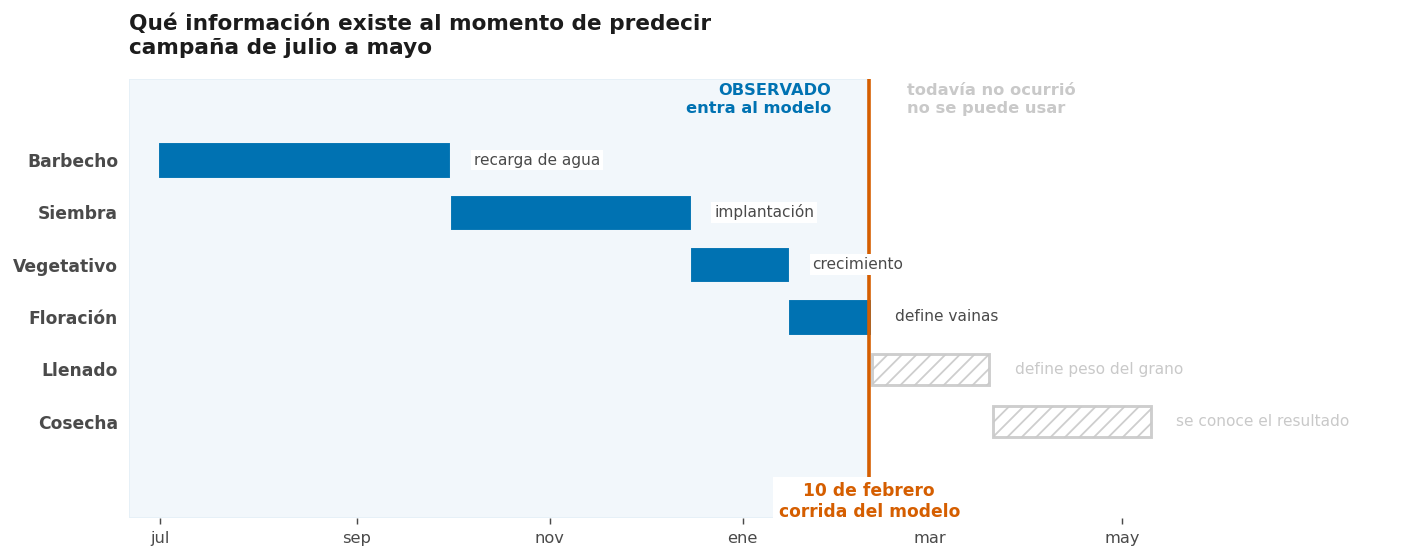

In [2]:
# ── Qué se sabe el 10 de febrero ─────────────────────────────────────────────
import datetime as dt
from matplotlib.patches import Rectangle

def dia(m, d, off=0):
    return (dt.date(2000 + off, m, d) - dt.date(2000, 7, 1)).days

VENT_T = [
    ("Barbecho",   dia(7, 1),     dia(9, 30),     "recarga de agua",       True),
    ("Siembra",    dia(10, 1),    dia(12, 15),    "implantación",          True),
    ("Vegetativo", dia(12, 16),   dia(1, 15, 1),  "crecimiento",           True),
    ("Floración",  dia(1, 16, 1), dia(2, 10, 1),  "define vainas",         True),
    ("Llenado",    dia(2, 11, 1), dia(3, 20, 1),  "define peso del grano", False),
    ("Cosecha",    dia(3, 21, 1), dia(5, 10, 1),  "se conoce el resultado", False),
]
CORTE = dia(2, 10, 1)
FIN = dia(5, 10, 1)

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.axvspan(-10, CORTE, color=AZUL, alpha=.05, zorder=0)
ax.axvline(CORTE, color=NARANJA, lw=2, zorder=4)

for i, (nombre, ini, fin, rol, obs) in enumerate(VENT_T):
    y = len(VENT_T) - i - 1
    ax.add_patch(Rectangle((ini, y - .3), fin - ini, .6, zorder=3,
                           facecolor=AZUL if obs else "white",
                           edgecolor=AZUL if obs else TENUE,
                           linewidth=1.6, alpha=1 if obs else .9,
                           hatch=None if obs else "///"))
    ax.text(fin + 8, y, rol, va="center", ha="left", fontsize=8.5,
            color=TINTA2 if obs else TENUE, zorder=4,
            bbox=dict(boxstyle="square,pad=.18", fc="white", ec="none"))

ax.text(CORTE - 12, len(VENT_T) - .15, "OBSERVADO\nentra al modelo", ha="right",
        va="bottom", fontsize=9, color=AZUL, weight="700")
ax.text(CORTE + 12, len(VENT_T) - .15, "todavía no ocurrió\nno se puede usar", ha="left",
        va="bottom", fontsize=9, color=TENUE, weight="600")
ax.text(CORTE, -1.15, "10 de febrero\ncorrida del modelo", ha="center", va="top",
        fontsize=9.5, color=NARANJA, weight="700", zorder=6,
        bbox=dict(boxstyle="square,pad=.3", fc="white", ec="none"))

meses = [(7, "jul", 0), (9, "sep", 0), (11, "nov", 0), (1, "ene", 1), (3, "mar", 1), (5, "may", 1)]
ax.set_xticks([dia(m, 1, o) for m, _, o in meses])
ax.set_xticklabels([n for _, n, _ in meses])
ax.set_yticks(range(len(VENT_T)))
ax.set_yticklabels([n for n, *_ in VENT_T][::-1], fontsize=9.5, weight="600")
ax.tick_params(length=0, axis="y", pad=6)
ax.set_ylim(-1.85, len(VENT_T) + .55); ax.set_xlim(-10, FIN + 80)
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Qué información existe al momento de predecir\ncampaña de julio a mayo")
plt.tight_layout(); plt.show()

Las barras llenas son las ventanas cerradas al 10 de febrero: **son las únicas
que pueden entrar al modelo**. Las rayadas ocurren después de la corrida, así que
usarlas sería predecir con información del futuro — el mismo error que se evitó
al excluir `produccion_tm` y `superficie_cosechada_ha` (sección 2.7).

Todo el análisis de la sección 4 respeta este corte.

### 1.4 Qué gana el negocio, en unidades del negocio

Sobre los 255 departamentos del panel, en la campaña 2022/23 —la peor sequía del
período:

| | Producción estimada del panel | Error contra lo real |
|---|---|---|
| Real observado | 27,3 Mt | — |
| Baseline (promedio histórico) | 42,3 Mt | **+15,0 Mt** |
| Modelo al 10 de febrero | 34,0 Mt | **+6,8 Mt** |

El criterio actual habría atravesado la sequía creyendo que la producción sería
un **55% mayor** que la real. El modelo, en febrero, recorta esa sobrestimación a
menos de la mitad: **8,3 Mt de exposición mejor dimensionada**, con dos meses de
anticipación sobre la cosecha.

El modelo tampoco acierta —también sobrestima— pero se equivoca mucho menos y a
tiempo. Para una compañía que debe constituir reservas antes de conocer el
siniestro, esa diferencia es la decisión.

### 1.5 Puesta en producción

Corrida **mensual entre enero y marzo**. Cada ejecución toma la superficie
sembrada declarada y el clima acumulado hasta la fecha, y devuelve el rendimiento
esperado por departamento; la estimación se refina a medida que cierran más
ventanas. Reentrenamiento anual al cerrar la campaña.

Con una salvedad que surge de la sección 3.10: hay que **recalcular también la
normal climática de referencia**, porque el clima del panel tiene tendencia y una
normal congelada envejece.

---
## 2. Dataset

### 2.1 Fuentes

| Fuente | Qué aporta | Actualización |
|---|---|---|
| **Estimaciones Agrícolas — MAGyP** | superficie sembrada y cosechada, producción y rendimiento por departamento y campaña, 41 cultivos desde 1969/70 | mensual durante la campaña; cierre anual |
| **NASA POWER (MERRA-2, comunidad AG)** | clima diario en el centroide de cada departamento: lluvia, temperaturas, radiación, humedad, viento | diaria, con unos días de rezago |

Ambas son públicas y programáticas, así que el dataset **se puede regenerar cada
campaña** corriendo los scripts `01`, `02b` y `04`.

### 2.2 El dataset crudo

Antes de cualquier transformación, así viene la fuente del MAGyP.

In [3]:
crudo = pd.read_csv("../data/raw/estimaciones_agricolas.csv")

print(f"{crudo.shape[0]:,} filas x {crudo.shape[1]} columnas")
print(f"{crudo.cultivo.nunique()} cultivos | {crudo.campania.nunique()} campañas "
      f"({crudo.campania.min()} a {crudo.campania.max()}) | "
      f"{crudo.departamento_id.nunique():.0f} departamentos\n")
display(crudo.head())

resumen = pd.DataFrame({
    "tipo": crudo.dtypes.astype(str),
    "nulos": crudo.isna().sum(),
    "% nulos": (crudo.isna().mean() * 100).round(2),
    "únicos": crudo.nunique(),
})
display(resumen)

print("Cultivos con más registros:")
print(crudo.cultivo.value_counts().head(6).to_string())

160,499 filas x 11 columnas
41 cultivos | 56 campañas (1969/1970 a 2024/2025) | 507 departamentos



,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,6.0,25 de Mayo,6854.0,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,6.0,Adolfo Gonzales Chaves,6014.0,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,6.0,Almirante Brown,6028.0,2,2,8,4000
3,ajo,1969,1969/1970,Buenos Aires,6.0,Balcarce,6063.0,450,450,2025,4500
4,ajo,1969,1969/1970,Buenos Aires,6.0,Cañuelas,6134.0,2,2,7,3500


,tipo,nulos,% nulos,únicos
cultivo,str,0,0.0,41
anio,int64,0,0.0,56
campania,str,0,0.0,56
provincia,str,8,0.0,23
provincia_id,float64,8,0.0,23
departamento,str,8,0.0,409
departamento_id,float64,8,0.0,507
superficie_sembrada_ha,int64,0,0.0,10090
superficie_cosechada_ha,int64,0,0.0,12130
produccion_tm,int64,0,0.0,23770


Cultivos con más registros:
cultivo
maíz           17725
trigo total    13292
sorgo          12135
soja total     11983
avena          11534
girasol        10647


La fuente cubre 41 cultivos y 56 campañas. Los ocho registros sin provincia ni
departamento corresponden a una categoría `sin definir` que la propia fuente usa
cuando no puede asignar la producción a una jurisdicción: se descartan.

**Se trabaja con `soja total`**, que agrega soja de primera y de segunda. Es la
serie más larga (las variantes 1ra y 2da existen recién desde 2000) y la que
corresponde al índice zonal que aseguraría la compañía, que no distingue fecha de
siembra.

### 2.3 Verificación de fuga de información

La sospecha es que `rendimiento_kgxha` no sea una medición independiente sino un
cociente de las otras dos columnas. Si así fuera, `produccion_tm` y
`superficie_cosechada_ha` **son la variable respuesta escrita de otra forma** y no
pueden usarse como features. Se verifica en vez de suponerlo.

rendimiento_kgxha  vs  produccion_tm x 1000 / superficie_cosechada_ha
  n = 11,854
  error mediano  : 0.091 kg/ha
  percentil 99   : 0.49 kg/ha
  coincidencia exacta (<1 kg/ha): 99.84% de los casos


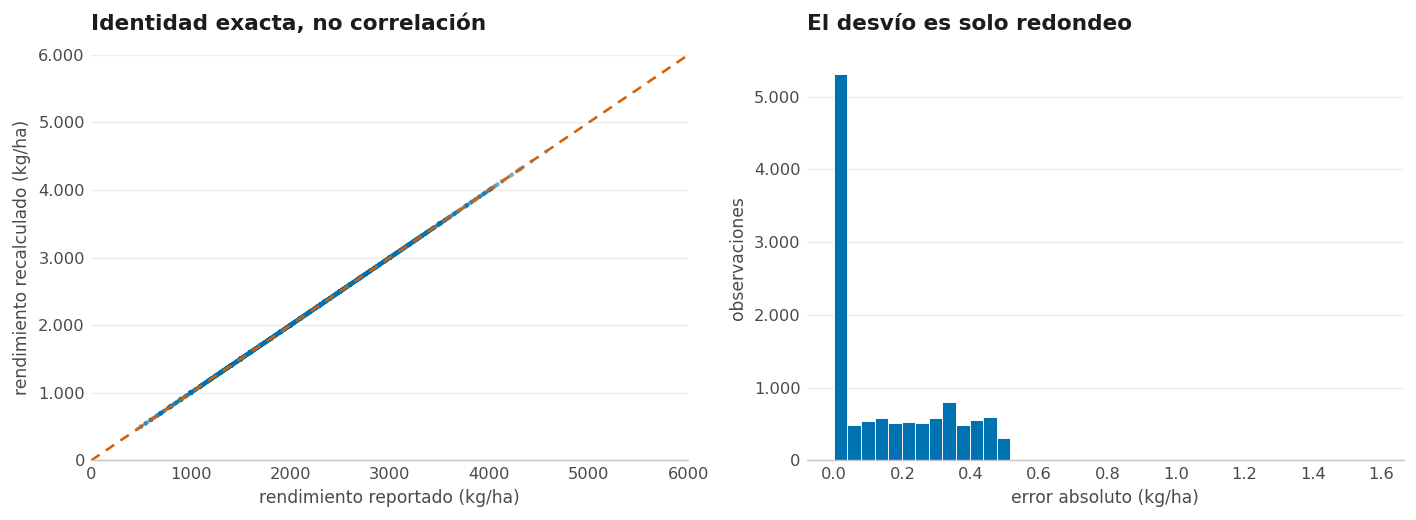

In [4]:
soja = crudo[crudo.cultivo == "soja total"].copy()
con_cosecha = soja[soja.superficie_cosechada_ha > 0].copy()
con_cosecha["rend_calculado"] = (con_cosecha.produccion_tm * 1000
                                 / con_cosecha.superficie_cosechada_ha)
err = (con_cosecha.rend_calculado - con_cosecha.rendimiento_kgxha).abs()

print(f"rendimiento_kgxha  vs  produccion_tm x 1000 / superficie_cosechada_ha")
print(f"  n = {len(con_cosecha):,}")
print(f"  error mediano  : {err.median():.3f} kg/ha")
print(f"  percentil 99   : {err.quantile(.99):.2f} kg/ha")
print(f"  coincidencia exacta (<1 kg/ha): {(err < 1).mean()*100:.2f}% de los casos")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.1))
m = con_cosecha.sample(3000, random_state=0)
a1.scatter(m.rendimiento_kgxha, m.rend_calculado, s=6, color=AZUL,
           alpha=.35, edgecolor="none")
lim = [0, 6000]
a1.plot(lim, lim, color=NARANJA, lw=1.4, ls=(0, (4, 3)))
a1.set_xlim(lim); a1.set_ylim(lim)
a1.set_xlabel("rendimiento reportado (kg/ha)")
a1.set_ylabel("rendimiento recalculado (kg/ha)")
a1.set_title("Identidad exacta, no correlación")
limpiar(a1)

a2.hist(err[err < 2], bins=40, color=AZUL, edgecolor="white", linewidth=.5)
a2.set_xlabel("error absoluto (kg/ha)"); a2.set_ylabel("observaciones")
a2.set_title("El desvío es solo redondeo")
limpiar(a2)
plt.tight_layout(); plt.show()

**Conclusión: es leakage.** El 99,8% de los registros coincide con menos de 1 kg/ha
de diferencia, y el residuo es redondeo de la fuente. Un modelo que usara
`produccion_tm` o `superficie_cosechada_ha` alcanzaría un error cercano a cero sin
haber aprendido nada: estaría leyendo la respuesta.

Ambas columnas se excluyen. **`superficie_sembrada_ha` sí se conserva**: se declara
al inicio de la campaña y es conocida en febrero, cuando corre el modelo.

### 2.4 Del crudo al panel

Cada filtro responde a un motivo explícito, y se documenta cuántas observaciones
cuesta.

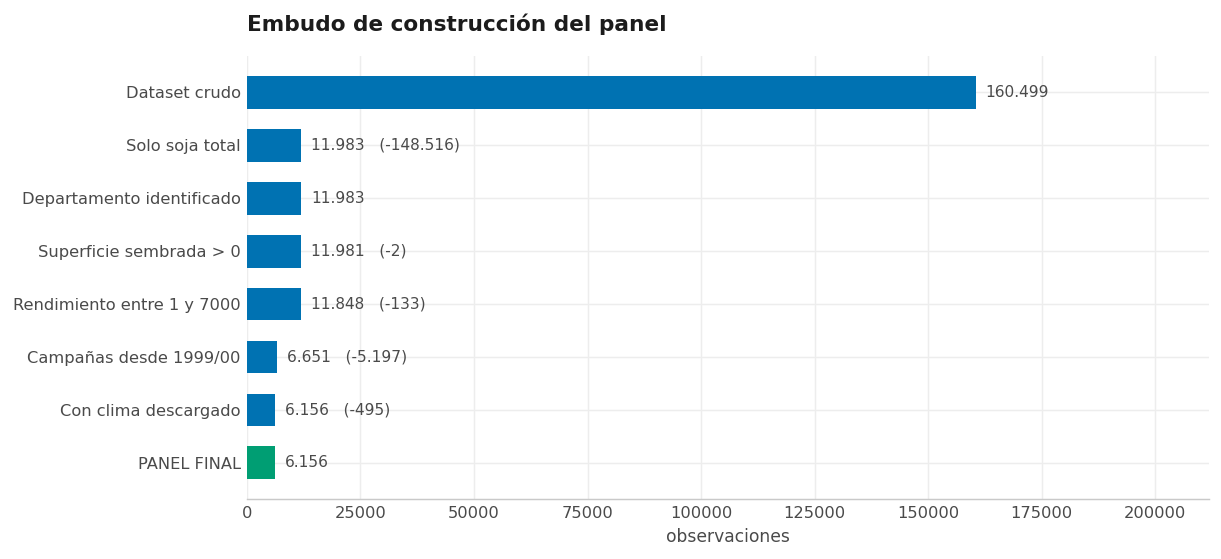

,paso,n,pierde,motivo
0,Dataset crudo,160499,0,"41 cultivos, 56 campañas"
1,Solo soja total,11983,-148516,el cultivo del caso de negocio
2,Departamento identificado,11983,0,descarta la categoría 'sin definir'
3,Superficie sembrada > 0,11981,-2,registros sin siembra declarada
4,Rendimiento entre 1 y 7000,11848,-133,2 outliers y 133 ceros técnicos
5,Campañas desde 1999/00,6651,-5197,NASA POWER arranca en 1999
6,Con clima descargado,6156,-495,319 deptos con ≥15 campañas en 4 cultivos
7,PANEL FINAL,6156,0,≥15 campañas por departamento


In [5]:
_panel = pd.read_csv("../data/processed/dataset_soja_total.csv",
                     usecols=["departamento_id", "anio"])

pasos, motivos = [], []
def paso(nombre, n, motivo):
    pasos.append((nombre, n)); motivos.append(motivo)

paso("Dataset crudo", len(crudo), "41 cultivos, 56 campañas")
s = crudo[crudo.cultivo == "soja total"]
paso("Solo soja total", len(s), "el cultivo del caso de negocio")
s = s.dropna(subset=["departamento_id"])
paso("Departamento identificado", len(s), "descarta la categoría 'sin definir'")
s = s[s.superficie_sembrada_ha > 0]
paso("Superficie sembrada > 0", len(s), "registros sin siembra declarada")
s = s[s.rendimiento_kgxha.between(1, 7000)]
paso("Rendimiento entre 1 y 7000", len(s), "2 outliers y 133 ceros técnicos")
s = s[s.anio >= 1999]
paso("Campañas desde 1999/00", len(s), "NASA POWER arranca en 1999")
s = s[s.departamento_id.isin(_panel.departamento_id.unique())]
paso("Con clima descargado", len(s), "319 deptos con ≥15 campañas en 4 cultivos")
paso("PANEL FINAL", len(_panel), "≥15 campañas por departamento")

emb = pd.DataFrame(pasos, columns=["paso", "n"])
emb["pierde"] = emb.n.diff().fillna(0).astype(int)
emb["motivo"] = motivos

fig, ax = plt.subplots(figsize=(9.5, 4.4))
y = np.arange(len(emb))[::-1]
ax.barh(y, emb.n, color=[VERDE if i == len(emb)-1 else AZUL for i in range(len(emb))],
        height=.62)
for yy, (n, p) in zip(y, zip(emb.n, emb.pierde)):
    ax.text(n + 2200, yy, f"{n:,}".replace(",", ".") + (f"   ({p:+,})".replace(",", ".") if p else ""),
            va="center", fontsize=8.5, color=TINTA2)
ax.set_yticks(y); ax.set_yticklabels(emb.paso, fontsize=9)
ax.set_xlim(0, len(crudo) * 1.32)
ax.set_xlabel("observaciones"); ax.set_title("Embudo de construcción del panel")
ax.grid(True, axis="x"); ax.tick_params(length=0)
plt.tight_layout(); plt.show()

display(emb[["paso", "n", "pierde", "motivo"]])

El recorte grande no es un filtro de calidad sino **una restricción de la fuente
climática**: NASA POWER desde 1999, por decisión de alcance del equipo. Es el precio de enriquecer con clima, y está asumido a conciencia — sin
clima el panel sería más largo pero el 63% de la varianza quedaría sin explicar
(sección 3.3).

Los filtros de calidad propiamente dichos cuestan **135 observaciones sobre 11.983**,
poco más del 1%.

### 2.5 El dataset final

In [6]:
d = pd.read_csv("../data/processed/dataset_soja_total.csv")
d["campania_lbl"] = d.anio.astype(str) + "/" + (d.anio + 1).astype(str).str[2:]

print(f"{d.shape[0]:,} observaciones x {d.shape[1]} columnas")
print(f"{d.departamento_id.nunique()} departamentos | {d.anio.nunique()} campañas "
      f"({d.campania_lbl.min()} a {d.campania_lbl.max()})")
print(f"{d.provincia.nunique()} provincias")
print(f"\nrendimiento: media {d.rendimiento_kgxha.mean():.0f} kg/ha, "
      f"desvío {d.rendimiento_kgxha.std():.0f}, "
      f"rango {d.rendimiento_kgxha.min():.0f}–{d.rendimiento_kgxha.max():.0f}")

display(d.head())

6,156 observaciones x 180 columnas
255 departamentos | 26 campañas (1999/00 a 2024/25)
14 provincias

rendimiento: media 2426 kg/ha, desvío 756, rango 219–4764


,anio,campania,provincia,departamento,departamento_id,superficie_sembrada_ha,rendimiento_kgxha,barbecho_pp_mm,barbecho_tmax_med,barbecho_tmin_med,...,anom_ciclo_et0_mm,anom_ciclo_balance_mm,anom_ciclo_racha_seca,anom_ciclo_hr_med,anom_ciclo_viento_med,lat,lon,area_km2,sup_sembrada_log,campania_lbl
0,1999,1999/2000,Buenos Aires,Adolfo Gonzales Chaves,6014,2500,2440,160.49,14.957609,3.595109,...,0.012812,0.069614,0.861169,0.162279,-2.015197,-37.9404,-60.2870,4785.9,7.824446,1999/00
1,1999,1999/2000,Buenos Aires,Alberti,6021,26500,1371,172.63,17.689130,5.002174,...,1.043061,-0.915466,0.685086,-1.005060,-1.080792,-35.0276,-60.2840,1357.6,10.184938,1999/00
2,1999,1999/2000,Buenos Aires,Ayacucho,6042,1000,2165,211.40,15.385870,3.809565,...,-0.118614,0.180426,0.571736,0.236901,-2.095121,-36.9764,-58.5931,8428.4,6.908755,1999/00
3,1999,1999/2000,Buenos Aires,Azul,6049,30500,2801,178.59,15.214239,3.499022,...,-0.495792,0.588511,0.313310,0.472884,-2.564071,-36.8368,-59.6811,8127.0,10.325515,1999/00
4,1999,1999/2000,Buenos Aires,Balcarce,6063,14600,2697,233.00,14.980870,3.975870,...,-0.035677,0.288128,0.251248,0.498235,-2.033495,-37.7463,-58.1898,5186.8,9.588845,1999/00


### 2.6 Cómo se construyó el clima

El clima diario no entra crudo al dataset. **Se agrega en ventanas fenológicas**,
porque el rendimiento no responde al clima "del año" sino a qué pasó en cada
etapa del cultivo: treinta milímetros en barbecho no valen lo mismo que treinta
milímetros en llenado de grano.

| Ventana | Período (campaña YYYY/YYYY+1) | Rol agronómico |
|---|---|---|
| barbecho | jul – sep YYYY | recarga de agua en el perfil |
| siembra | oct – 15 dic YYYY | implantación |
| vegetativo | 16 dic – 15 ene | crecimiento |
| floración | 16 ene – 10 feb | R1–R2, definición de vainas |
| **llenado** | **11 feb – 20 mar** | **R3–R6, define el peso del grano** |
| cosecha | 21 mar – 10 may | acá la lluvia es un problema, no un beneficio |
| ciclo | oct YYYY – abr YYYY+1 | agregado total |

De cada ventana salen doce indicadores: lluvia acumulada, temperaturas media,
máxima y mínima, días de calor extremo (>32 °C), días de helada (<3 °C),
radiación, evapotranspiración de referencia por Hargreaves-Samani, balance
hídrico, racha seca máxima, humedad relativa y viento.

Y de cada indicador, además, su **anomalía** contra la normal del propio
departamento, expresada en desvíos propios. Esto separa "este departamento es
seco" de "este año fue seco acá", que son dos señales distintas.

In [7]:
VENTANAS = ["barbecho", "siembra", "vegetativo", "floracion", "llenado", "cosecha", "ciclo"]
clima_abs = [c for c in d.columns if any(c.startswith(v + "_") for v in VENTANAS)]
clima_ano = [c for c in d.columns if c.startswith("anom_")]
estruct = ["lat", "lon", "area_km2", "sup_sembrada_log", "anio"]

print(f"features climáticas absolutas : {len(clima_abs)}")
print(f"features de anomalía          : {len(clima_ano)}")
print(f"features estructurales        : {len(estruct)}")
print(f"total de predictores          : {len(clima_abs) + len(clima_ano) + len(estruct)}")

features climáticas absolutas : 84
features de anomalía          : 84
features estructurales        : 5
total de predictores          : 173


### 2.7 Decisiones y limitaciones

**Variables excluidas por fuga de información.** En la fuente original,
`rendimiento = produccion_tm × 1000 / superficie_cosechada_ha`; lo verificamos y
el error mediano es de 0,09 kg/ha. Producción y superficie cosechada **son el
target escrito de otra forma** y no están en el dataset. La única superficie que
sobrevive es la **sembrada**, que se conoce antes de la cosecha.

**La normal climática se calcula solo con campañas hasta 2018**, es decir sin
tocar el período de evaluación (2020/21 en adelante). Calcularla sobre la serie
completa filtraría información del futuro hacia el entrenamiento.

**Limitaciones a declarar:**

- **Granularidad espacial.** El departamento es la unidad mínima publicada. Dentro
  de uno conviven suelos y fechas de siembra muy distintos, y el clima se toma del
  centroide, que representa peor a los departamentos grandes del norte.
- **Resolución del clima.** MERRA-2 va a ~0,5° × 0,625°, más grueso que ERA5.
  Aceptable para agregados departamentales, no para lote.
- **Ausencia de suelo y manejo.** No hay tipo de suelo, agua útil, fecha de
  siembra, variedad, fertilización ni incidencia de plagas. Buena parte del
  residuo del modelo vive ahí.
- **Las estimaciones del MAGyP se revisan.** Una campaña puede cambiar de valor
  después de publicada.
- **El clima empieza en 1999**, así que el panel arranca en 1999/2000 aunque el
  rendimiento exista desde 1969/70.

### 2.8 Diccionario de datos

179 columnas no se leen de una. Antes de explorar conviene fijar qué es cada
una: tipo de dato, unidad, y a qué grupo pertenece.

In [8]:
no_clima = [c for c in d.columns if c not in clima_abs and c not in clima_ano
            and c != "campania_lbl"]

print("Tipos de dato en las 179 columnas originales:")
print(d[[c for c in d.columns if c != "campania_lbl"]].dtypes.value_counts().to_string())
print()
print(f"Columnas no climáticas ({len(no_clima)}):")
for c in no_clima:
    print(f"  {c:24s} {str(d[c].dtype):10s} {d[c].nunique():>6,} valores únicos")

Tipos de dato en las 179 columnas originales:
float64    151
int64       25
str          3

Columnas no climáticas (11):
  anio                     int64          26 valores únicos
  campania                 str            26 valores únicos
  provincia                str            14 valores únicos
  departamento             str           225 valores únicos
  departamento_id          int64         255 valores únicos
  superficie_sembrada_ha   int64       2,613 valores únicos
  rendimiento_kgxha        int64       2,325 valores únicos
  lat                      float64       254 valores únicos
  lon                      float64       255 valores únicos
  area_km2                 float64       255 valores únicos
  sup_sembrada_log         float64     2,613 valores únicos


**Columnas no climáticas** (11; `campania` es redundante con `anio` — se ignora):

| Columna | Tipo | Qué es |
|---|---|---|
| `anio` | int | año de inicio de campaña (2020 = campaña 2020/21) |
| `campania` | texto | igual que `anio`, en formato "2020/2021" — no se usa como feature |
| `provincia`, `departamento` | texto | identificadores geográficos, solo para agrupar y graficar |
| `departamento_id` | int | código INDEC del departamento — clave del panel junto con `anio` |
| `superficie_sembrada_ha` | int | hectáreas sembradas en la campaña |
| `sup_sembrada_log` | float | `log(superficie_sembrada_ha)`, la versión que se usa como predictor |
| `rendimiento_kgxha` | int | **target**: kg de soja por hectárea cosechada |
| `lat`, `lon` | float | centroide del departamento |
| `area_km2` | float | superficie total del departamento (no solo la sembrada) |

**Los 168 predictores climáticos** son 12 indicadores × 7 ventanas fenológicas
× 2 versiones (absoluta y anomalía). El nombre de columna sigue siempre el
patrón `{ventana}_{indicador}` o `anom_{ventana}_{indicador}` — por ejemplo
`llenado_pp_mm` es la lluvia acumulada en la ventana de llenado, y
`anom_llenado_pp_mm` es esa misma lluvia expresada en desvíos contra la normal
del departamento. Las ventanas están en la sección 2.6; los 12 indicadores son:

| Indicador | Qué mide | Unidad |
|---|---|---|
| `pp_mm` | lluvia acumulada | mm |
| `tmax_med`, `tmin_med`, `tmed` | temperatura media, de las máximas y de las mínimas diarias | °C |
| `dias_calor` | días con temperatura máxima > 32 °C | días |
| `dias_helada` | días con temperatura mínima < 3 °C | días |
| `rad_med` | radiación solar media | MJ/m²/día |
| `et0_mm` | evapotranspiración de referencia (Hargreaves–Samani) | mm |
| `balance_mm` | lluvia − ET0, balance hídrico simple | mm |
| `racha_seca` | racha máxima de días consecutivos sin lluvia | días |
| `hr_med` | humedad relativa media | % |
| `viento_med` | velocidad media del viento | m/s |

Todos los predictores climáticos son `float64`; no hay columnas de texto ni de
fecha entre ellos, así que no requieren encoding antes de modelar.

---
## 3. Análisis exploratorio

### 3.1 La variable respuesta

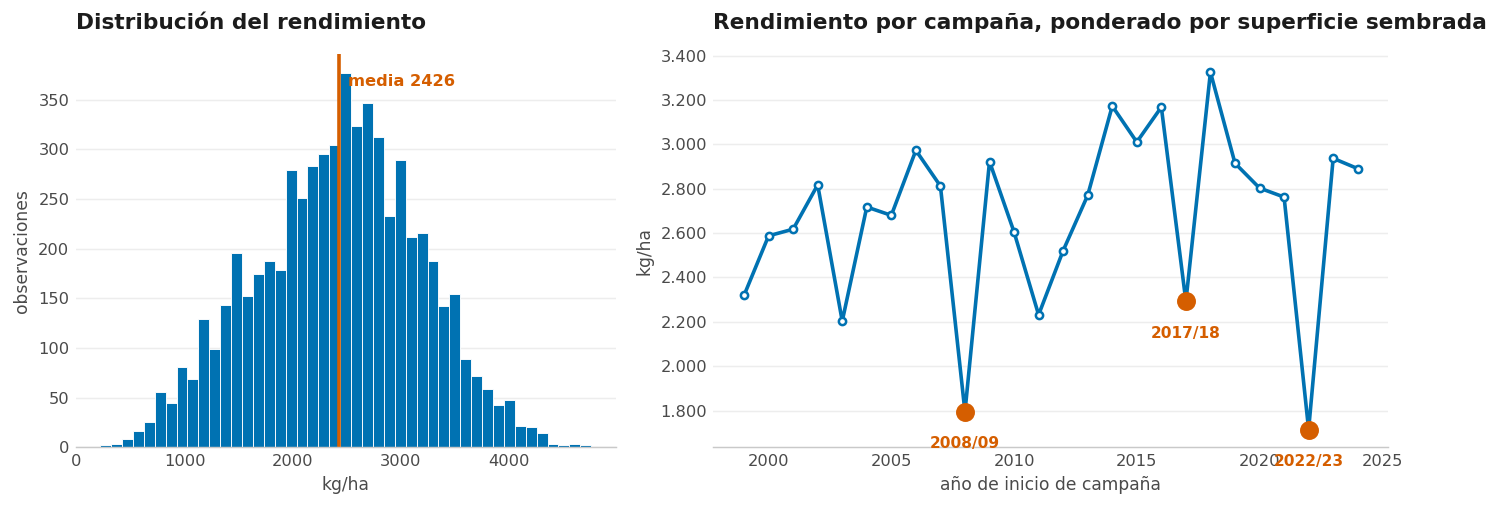

Las tres campañas marcadas son sequías. La peor, 2022/23, cae a 1715 kg/ha contra 2772 de un año sin sequía: 38% menos.


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})

a1.hist(d.rendimiento_kgxha, bins=45, color=AZUL, edgecolor="white", linewidth=.5)
a1.axvline(d.rendimiento_kgxha.mean(), color=NARANJA, lw=2)
a1.text(d.rendimiento_kgxha.mean() + 90, a1.get_ylim()[1] * .92,
        f"media {d.rendimiento_kgxha.mean():.0f}", color=NARANJA, fontsize=9, weight="600")
a1.set_title("Distribución del rendimiento")
a1.set_xlabel("kg/ha"); a1.set_ylabel("observaciones")
limpiar(a1)

# Rendimiento medio por campaña, ponderado por superficie sembrada
pc = (d.groupby("anio")
        .apply(lambda g: np.average(g.rendimiento_kgxha, weights=g.superficie_sembrada_ha))
        .rename("rend"))
a2.plot(pc.index, pc.values, color=AZUL, lw=2, marker="o", ms=4,
        markerfacecolor="white", markeredgewidth=1.4)
SEQUIAS = {2008: "2008/09", 2017: "2017/18", 2022: "2022/23"}
for a, lbl in SEQUIAS.items():
    if a in pc.index:
        a2.scatter([a], [pc[a]], s=90, color=NARANJA, zorder=5)
        a2.annotate(lbl, (a, pc[a]), textcoords="offset points", xytext=(0, -20),
                    ha="center", fontsize=8.5, color=NARANJA, weight="600")
a2.set_title("Rendimiento por campaña, ponderado por superficie sembrada")
a2.set_ylabel("kg/ha"); a2.set_xlabel("año de inicio de campaña")
limpiar(a2)
plt.tight_layout(); plt.show()

print(f"Las tres campañas marcadas son sequías. La peor, 2022/23, cae a "
      f"{pc.get(2022, float('nan')):.0f} kg/ha contra {pc.drop(list(SEQUIAS)).mean():.0f} "
      f"de un año sin sequía: {(1 - pc.get(2022) / pc.drop(list(SEQUIAS)).mean())*100:.0f}% menos.")

La serie muestra dos cosas a la vez: una **tendencia creciente** de fondo, por
mejora genética y de manejo, y **caídas abruptas** en años puntuales. Esas caídas
son el riesgo que el negocio necesita anticipar, y no siguen ningún patrón
temporal — no se predicen con el calendario.

### 3.2 Estructura espacial

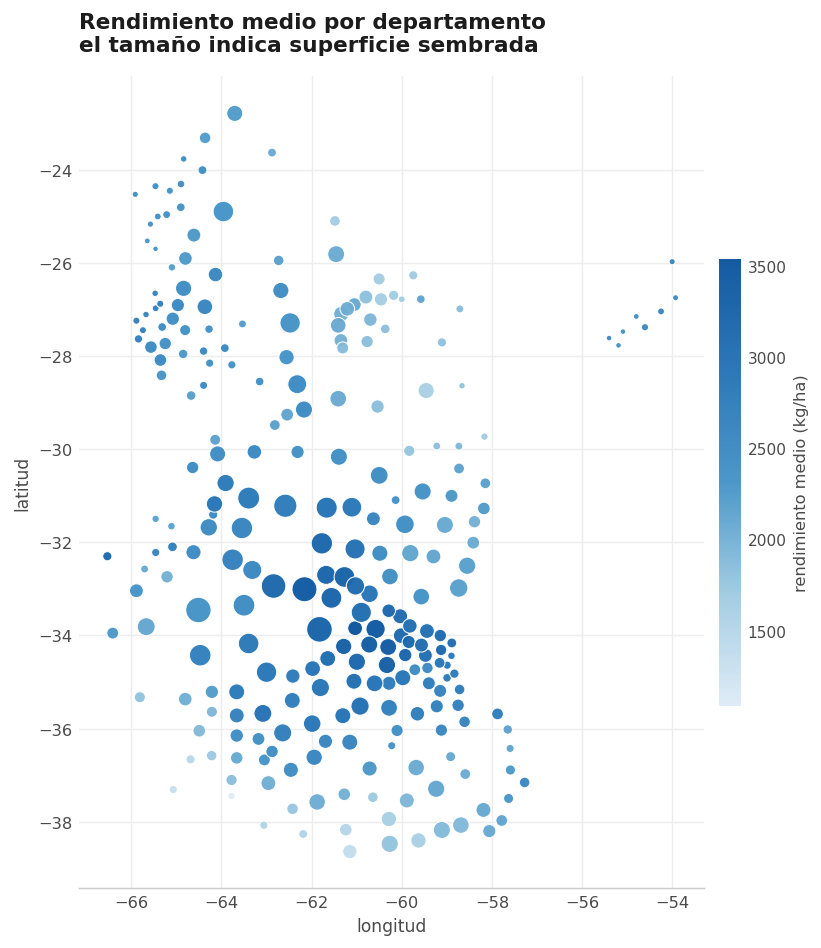

                     rend_medio  deptos
provincia                              
Santa Fe                 2689.0      19
Córdoba                  2616.0      23
Buenos Aires             2578.0      88
Tucumán                  2559.0      13
Misiones                 2453.0       8
Jujuy                    2403.0       5
Catamarca                2399.0       2
Santiago del Estero      2372.0      22
Salta                    2287.0      14
San Luis                 2287.0       8
Entre Ríos               2225.0      16
La Pampa                 1961.0      13
Chaco                    1868.0      20
Corrientes               1804.0       4


In [10]:
geo = (d.groupby(["departamento_id", "provincia", "departamento"])
         .agg(rend=("rendimiento_kgxha", "mean"), lat=("lat", "first"),
              lon=("lon", "first"), sup=("superficie_sembrada_ha", "mean"))
         .reset_index())

fig, ax = plt.subplots(figsize=(6.6, 7.4))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
sc = ax.scatter(geo.lon, geo.lat, c=geo.rend, s=np.sqrt(geo.sup) / 4 + 8,
                cmap=cmap, edgecolor="white", linewidth=.6, alpha=.95)
cb = fig.colorbar(sc, ax=ax, shrink=.55, pad=.02)
cb.set_label("rendimiento medio (kg/ha)", fontsize=9, color=TINTA2)
cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=8.5)
ax.set_title("Rendimiento medio por departamento\nel tamaño indica superficie sembrada")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.grid(True, axis="both"); ax.tick_params(length=0)
plt.tight_layout(); plt.show()

print(geo.groupby("provincia").rend.agg(["mean", "count"])
        .rename(columns={"mean": "rend_medio", "count": "deptos"})
        .sort_values("rend_medio", ascending=False).round(0).to_string())

Se distingue el **núcleo sojero** —sur de Santa Fe, sudeste de Córdoba, norte de
Buenos Aires— con los rendimientos más altos y las mayores superficies. Hacia el
norte (Chaco, Santiago del Estero, Salta) y hacia el sur y oeste los rendimientos
caen y la superficie se achica: son zonas marginales, más expuestas al clima.

### 3.3 ¿Cuánto hay realmente para explicar?

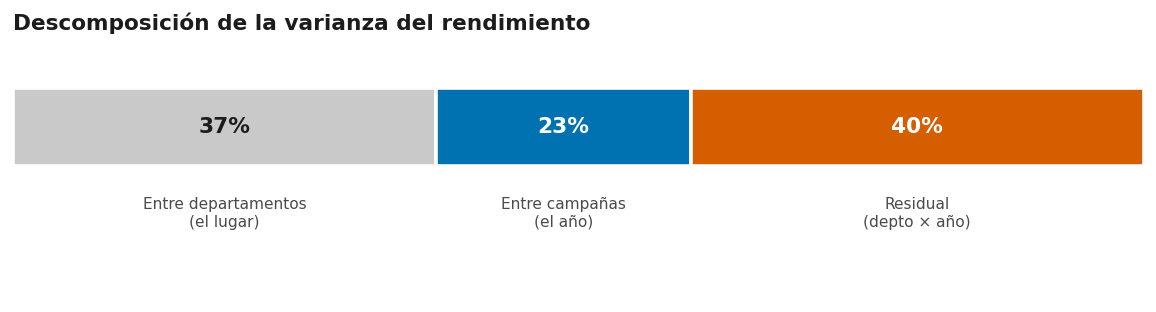

Desvío total: 756 kg/ha
El promedio histórico del departamento explica 37%.
Queda 63% que solo puede venir del año: 23% de clima regional y 40% de clima local.


In [11]:
y, gm = d.rendimiento_kgxha, d.rendimiento_kgxha.mean()
ef_dep = d.groupby("departamento_id").rendimiento_kgxha.transform("mean") - gm
ef_cam = d.groupby("anio").rendimiento_kgxha.transform("mean") - gm
resid = y - gm - ef_dep - ef_cam
tot = y.var()

partes = pd.Series({
    "Entre departamentos\n(el lugar)": ef_dep.var() / tot,
    "Entre campañas\n(el año)": ef_cam.var() / tot,
    "Residual\n(depto × año)": resid.var() / tot,
}) * 100

fig, ax = plt.subplots(figsize=(9, 2.5))
izq = 0
for (nombre, v), col in zip(partes.items(), [TENUE, AZUL, NARANJA]):
    ax.barh([0], [v], left=izq, color=col, height=.5,
            edgecolor="white", linewidth=2)
    ax.text(izq + v / 2, 0, f"{v:.0f}%", ha="center", va="center",
            color="white" if col != TENUE else TINTA, fontsize=12, weight="700")
    ax.text(izq + v / 2, -.45, nombre, ha="center", va="top", fontsize=8.5, color=TINTA2)
    izq += v
ax.set_xlim(0, 100); ax.set_ylim(-1.1, .5); ax.axis("off")
ax.set_title("Descomposición de la varianza del rendimiento", pad=10)
plt.tight_layout(); plt.show()

print(f"Desvío total: {y.std():.0f} kg/ha")
print(f"El promedio histórico del departamento explica {partes.iloc[0]:.0f}%.")
print(f"Queda {100 - partes.iloc[0]:.0f}% que solo puede venir del año: "
      f"{partes.iloc[1]:.0f}% de clima regional y {partes.iloc[2]:.0f}% de clima local.")

**Este es el gráfico que ordena todo el trabajo.** Saber *dónde* está el campo
explica poco más de un tercio de la varianza. El resto depende del año — y el
40% residual, que es la porción más grande, es específicamente la interacción
departamento × campaña: el clima local de ese lugar en ese año.

Eso es exactamente lo que las features climáticas están construidas para
capturar, y justifica el enriquecimiento **antes** de haber entrenado nada.

### 3.4 La firma de una sequía

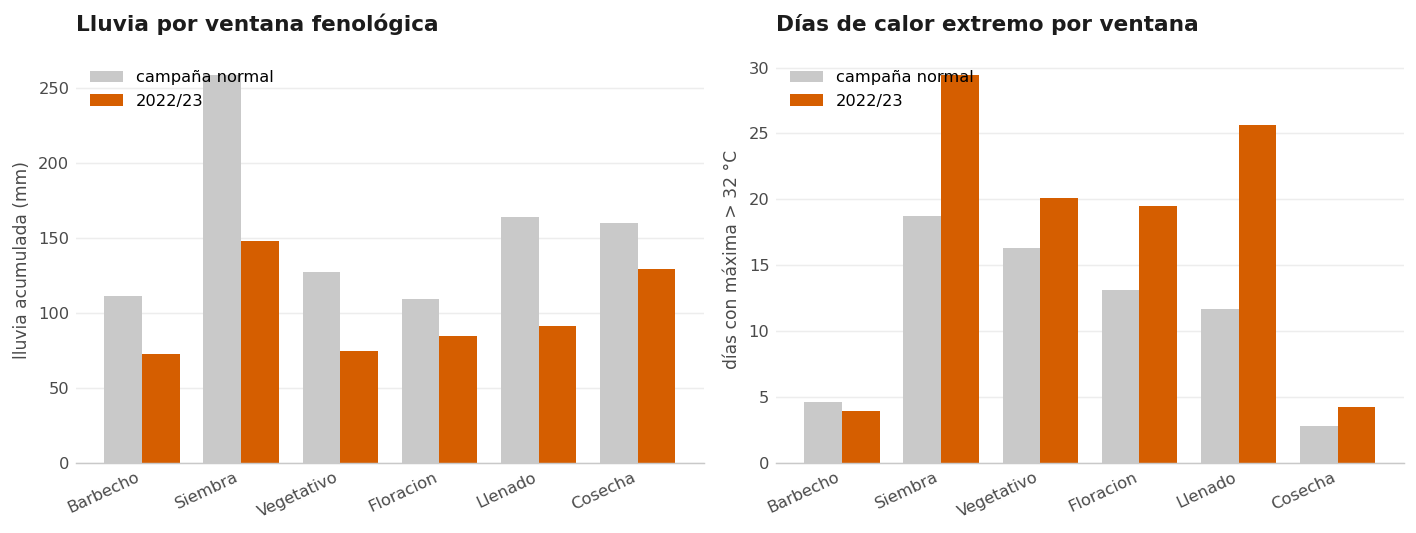

Déficit de lluvia 2022/23 contra campaña normal:
  Barbecho       -34%
  Siembra        -43%
  Vegetativo     -41%
  Floracion      -22%
  Llenado        -44%
  Cosecha        -19%


In [12]:
NORMAL = [a for a in d.anio.unique() if a not in (2008, 2017, 2022)]
pp = [f"{v}_pp_mm" for v in VENTANAS[:-1]]
comp = pd.DataFrame({
    "normal": d[d.anio.isin(NORMAL)][pp].mean(),
    "2022/23": d[d.anio == 2022][pp].mean(),
})
comp.index = [v.capitalize() for v in VENTANAS[:-1]]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(comp)); w = .38
a1.bar(x - w/2, comp["normal"], w, color=TENUE, label="campaña normal")
a1.bar(x + w/2, comp["2022/23"], w, color=NARANJA, label="2022/23")
a1.set_xticks(x); a1.set_xticklabels(comp.index, rotation=25, ha="right")
a1.set_ylabel("lluvia acumulada (mm)")
a1.set_title("Lluvia por ventana fenológica")
a1.legend(loc="upper left"); limpiar(a1)

calor = [f"{v}_dias_calor" for v in VENTANAS[:-1]]
cc = pd.DataFrame({"normal": d[d.anio.isin(NORMAL)][calor].mean(),
                   "2022/23": d[d.anio == 2022][calor].mean()})
cc.index = comp.index
a2.bar(x - w/2, cc["normal"], w, color=TENUE, label="campaña normal")
a2.bar(x + w/2, cc["2022/23"], w, color=NARANJA, label="2022/23")
a2.set_xticks(x); a2.set_xticklabels(cc.index, rotation=25, ha="right")
a2.set_ylabel("días con máxima > 32 °C")
a2.set_title("Días de calor extremo por ventana")
a2.legend(loc="upper left"); limpiar(a2)
plt.tight_layout(); plt.show()

dif = (comp["2022/23"] / comp["normal"] - 1) * 100
print("Déficit de lluvia 2022/23 contra campaña normal:")
for k, v in dif.items(): print(f"  {k:12s} {v:+5.0f}%")

La sequía no es uniforme: se concentra en las ventanas que definen el
rendimiento. En **llenado de grano** cae la lluvia y al mismo tiempo se disparan
los días de calor extremo — la peor combinación posible, porque la planta
necesita más agua justo cuando hay menos.

### 3.5 Relación entre clima y rendimiento

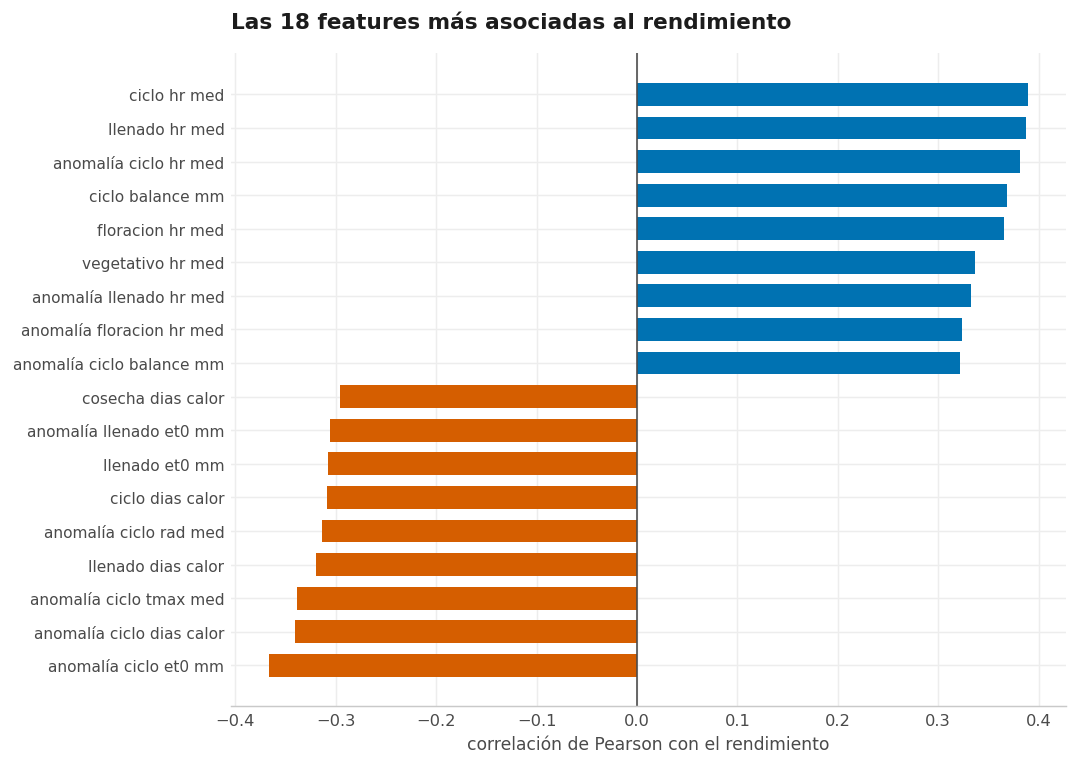

Ninguna supera |r| = 0,40 por sí sola: la señal es multivariada.


In [13]:
cor = d[clima_abs + clima_ano].corrwith(d.rendimiento_kgxha).dropna()
top = pd.concat([cor.nsmallest(9), cor.nlargest(9)]).sort_values()

fig, ax = plt.subplots(figsize=(8.4, 6))
col = [NARANJA if v < 0 else AZUL for v in top.values]
ax.barh(range(len(top)), top.values, color=col, height=.68)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([t.replace("anom_", "anomalía ").replace("_", " ") for t in top.index],
                   fontsize=8.5)
ax.axvline(0, color=TINTA2, lw=.9)
ax.set_xlabel("correlación de Pearson con el rendimiento")
ax.set_title("Las 18 features más asociadas al rendimiento")
ax.grid(True, axis="x"); ax.tick_params(length=0)
ax.yaxis.set_major_formatter(plt.NullFormatter()) if False else None
plt.tight_layout(); plt.show()

print("Ninguna supera |r| = 0,40 por sí sola: la señal es multivariada.")

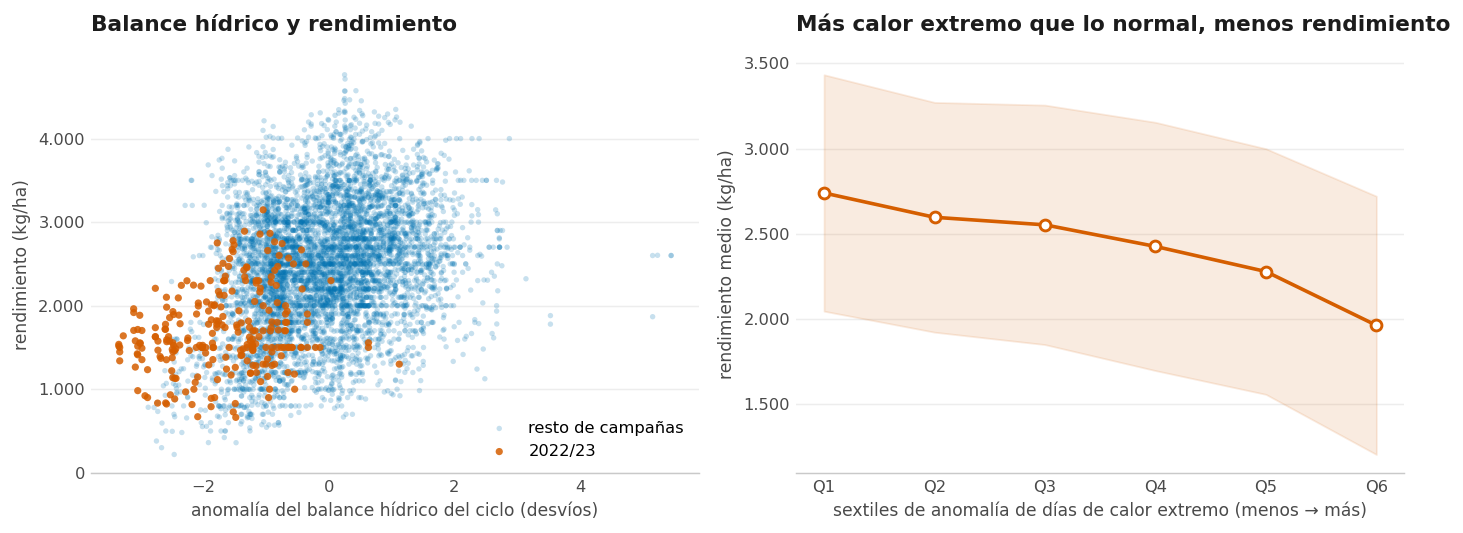

Del sextil con menos calor al de más: 2740 -> 1963 kg/ha (-28%).


In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))

sec = d.anio == 2022
a1.scatter(d.loc[~sec, "anom_ciclo_balance_mm"], d.loc[~sec, "rendimiento_kgxha"],
           s=9, color=AZUL, alpha=.22, edgecolor="none", label="resto de campañas")
a1.scatter(d.loc[sec, "anom_ciclo_balance_mm"], d.loc[sec, "rendimiento_kgxha"],
           s=16, color=NARANJA, alpha=.85, edgecolor="none", label="2022/23")
a1.set_xlabel("anomalía del balance hídrico del ciclo (desvíos)")
a1.set_ylabel("rendimiento (kg/ha)")
a1.set_title("Balance hídrico y rendimiento")
a1.legend(loc="lower right"); limpiar(a1)

q = pd.qcut(d.anom_ciclo_dias_calor, 6, duplicates="drop")
g = d.groupby(q, observed=True).rendimiento_kgxha.agg(["mean", "std", "size"])
a2.plot(range(len(g)), g["mean"], color=NARANJA, lw=2, marker="o", ms=6,
        markerfacecolor="white", markeredgewidth=1.6)
a2.fill_between(range(len(g)), g["mean"] - g["std"], g["mean"] + g["std"],
                color=NARANJA, alpha=.12)
a2.set_xticks(range(len(g)))
a2.set_xticklabels([f"Q{i+1}" for i in range(len(g))])
a2.set_xlabel("sextiles de anomalía de días de calor extremo (menos → más)")
a2.set_ylabel("rendimiento medio (kg/ha)")
a2.set_title("Más calor extremo que lo normal, menos rendimiento")
limpiar(a2)
plt.tight_layout(); plt.show()

print(f"Del sextil con menos calor al de más: "
      f"{g['mean'].iloc[0]:.0f} -> {g['mean'].iloc[-1]:.0f} kg/ha "
      f"({(g['mean'].iloc[-1]/g['mean'].iloc[0]-1)*100:.0f}%).")

### 3.6 Calidad de los datos

In [15]:
print(f"Faltantes: {d.isna().sum().sum()} celdas en total sobre {d.size:,}.")
print(f"Duplicados departamento × campaña: {d.duplicated(['departamento_id','anio']).sum()}")

sin_var = [c for c in d.columns if d[c].nunique() <= 1]
print(f"\nColumnas sin varianza (se descartan al modelar): {len(sin_var)}")
for c in sin_var: print(f"  - {c}")

obs = d.groupby("departamento_id").size()
print(f"\nCampañas por departamento: mediana {obs.median():.0f}, "
      f"mínimo {obs.min()}, máximo {obs.max()}")

q1, q3 = d.rendimiento_kgxha.quantile([.25, .75])
lim = q3 + 3 * (q3 - q1)
ext = d[d.rendimiento_kgxha > lim]
print(f"\nRendimientos extremos (> Q3 + 3·IQR = {lim:.0f} kg/ha): {len(ext)}")
print("Los rendimientos muy bajos NO son outliers: son pérdidas de campaña reales.")
print(f"  observaciones por debajo de 1000 kg/ha: {(d.rendimiento_kgxha < 1000).sum()}")

Faltantes: 0 celdas en total sobre 1,108,080.
Duplicados departamento × campaña: 0

Columnas sin varianza (se descartan al modelar): 3
  - floracion_dias_helada
  - anom_vegetativo_dias_helada
  - anom_floracion_dias_helada

Campañas por departamento: mediana 26, mínimo 15, máximo 26

Rendimientos extremos (> Q3 + 3·IQR = 6120 kg/ha): 0
Los rendimientos muy bajos NO son outliers: son pérdidas de campaña reales.
  observaciones por debajo de 1000 kg/ha: 198


**"Cero faltantes" no significa panel completo.** El dataset no tiene celdas
vacías porque una fila solo existe cuando el MAGyP reportó siembra de soja en
ese departamento esa campaña — si un departamento no sembró (o no se publicó
el dato), directamente **no hay fila**, no una fila con `NaN`. Eso es distinto
de "faltante" en el sentido de defecto de carga, pero igual hay que
caracterizarlo, porque afecta cuántas observaciones tiene cada departamento
para entrenar.

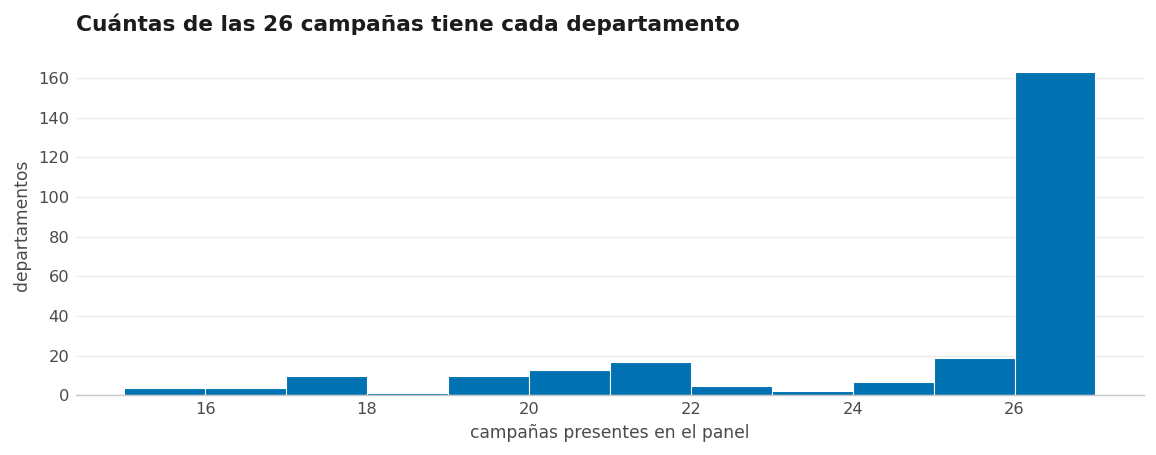

92 de 255 departamentos tienen menos de las 26 campañas completas.
De esos, 80 entraron al panel después de 1999/00 (consistente con la frontera agrícola de la sección 3.9).

Ejemplo — Curuzú Cuatiá (Corrientes), campañas presentes: [1999, 2000, 2001, 2002, 2003, 2007, 2008, 2009, 2010, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
No es una cola: faltan bloques enteros en el medio (2004–2006, 2011–2017),
años en que el departamento no tuvo superficie de soja reportada.


In [16]:
obs = d.groupby("departamento_id").anio.agg(["size", "min"]).rename(columns={"size": "n", "min": "primer_anio"})
incompletos = obs[obs.n < obs.n.max()]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(obs.n, bins=range(int(obs.n.min()), int(obs.n.max()) + 2), color=AZUL,
        edgecolor="white", linewidth=.6)
ax.set_xlabel("campañas presentes en el panel"); ax.set_ylabel("departamentos")
ax.set_title("Cuántas de las 26 campañas tiene cada departamento")
limpiar(ax)
plt.tight_layout(); plt.show()

print(f"{len(incompletos)} de {obs.shape[0]} departamentos tienen menos de las {obs.n.max()} campañas completas.")
print(f"De esos, {(incompletos.primer_anio > 1999).sum()} entraron al panel después de 1999/00 "
      f"(consistente con la frontera agrícola de la sección 3.9).")

# ejemplo de que no siempre es "entró tarde": también hay huecos en el medio
ej = d[d.departamento_id == 18035].sort_values("anio").anio.tolist()
print(f"\nEjemplo — Curuzú Cuatiá (Corrientes), campañas presentes: {ej}")
print("No es una cola: faltan bloques enteros en el medio (2004–2006, 2011–2017),")
print("años en que el departamento no tuvo superficie de soja reportada.")

El panel es **desbalanceado por diseño**, no por error de carga: 92 de 255
departamentos (36%) tienen menos de las 26 campañas completas, y la mayoría
entró tarde — la frontera agrícola de la sección 3.9 vista departamento por
departamento. Pero también hay departamentos, como Curuzú Cuatiá, que entran,
salen y vuelven a entrar: hectáreas marginales donde la soja se siembra solo
cuando el año lo justifica.

**Consecuencia para el modelado:** un departamento con 15 campañas tiene una
media histórica mucho menos confiable que uno con 26 — el baseline de la
sección 4 (media por departamento) es más ruidoso justo en las zonas más
nuevas y más marginales, que son además las de mayor riesgo climático. Es otro
argumento a favor del modelo con clima sobre el promedio histórico: en las
zonas donde menos historia hay, el promedio es menos confiable todavía.

### 3.7 Multicolinealidad entre features climáticas

Las 173 features climáticas no son 173 señales independientes. Dentro de una
misma ventana, temperatura, evapotranspiración y días de calor extremo son
formas distintas de medir lo mismo. Importa saberlo antes de modelar: no
invalida un modelo de árboles, pero sí a cualquier lectura de un coeficiente
lineal o de una importancia individual como si la variable actuara sola.

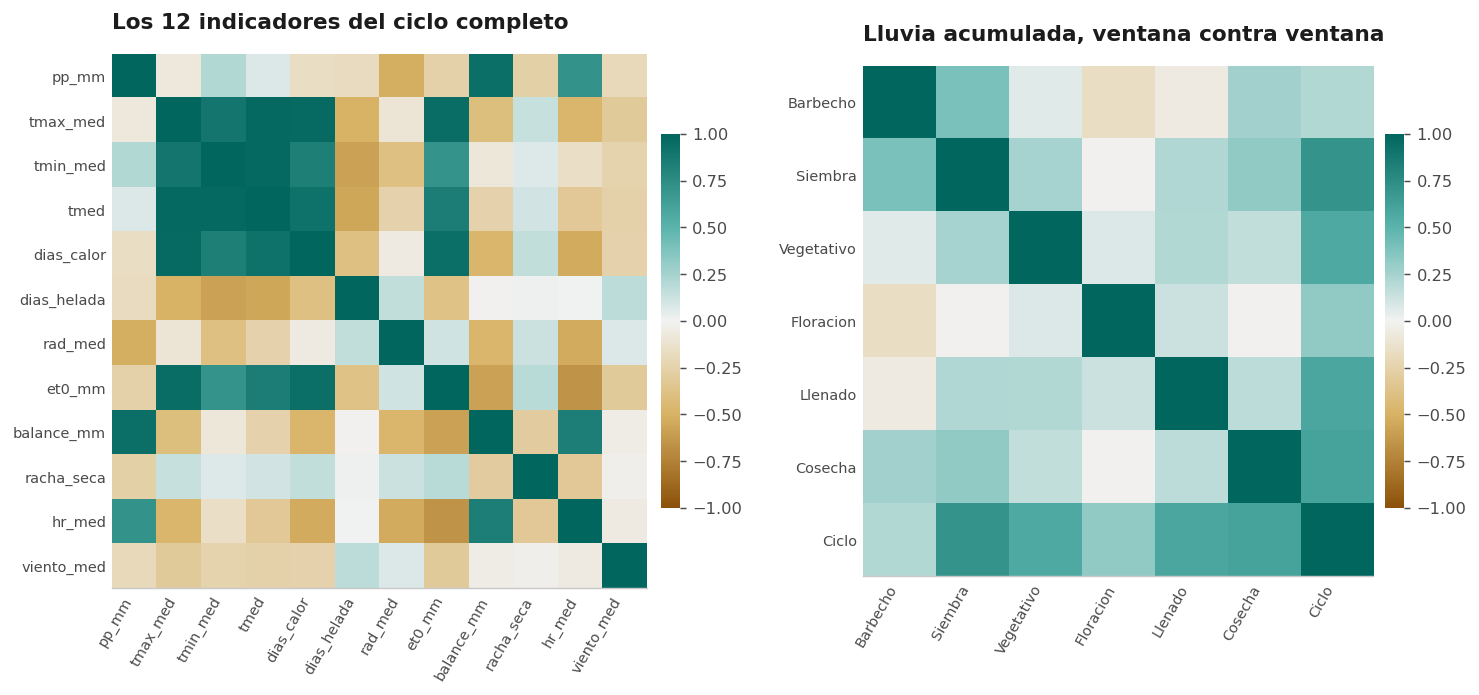

Pares con |r| > 0.85 dentro del ciclo: 8 de 66 posibles.
  ciclo_tmin_med       ciclo_tmed           r=+0.97
  ciclo_tmax_med       ciclo_tmed           r=+0.97
  ciclo_tmax_med       ciclo_dias_calor     r=+0.96
  ciclo_tmax_med       ciclo_et0_mm         r=+0.95
  ciclo_dias_calor     ciclo_et0_mm         r=+0.94
  ciclo_pp_mm          ciclo_balance_mm     r=+0.94
  ciclo_tmed           ciclo_dias_calor     r=+0.92
  ciclo_tmax_med       ciclo_tmin_med       r=+0.89

Lluvia de siembra vs. lluvia del ciclo completo: r=0.71


In [17]:
cmap_div = LinearSegmentedColormap.from_list("div", DIV)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})

# Panel 1: correlación entre los 12 indicadores del ciclo completo
ciclo_vars = [c for c in d.columns if c.startswith("ciclo_")]
et1 = [c.replace("ciclo_", "") for c in ciclo_vars]
corr1 = d[ciclo_vars].corr()
im1 = a1.imshow(corr1, cmap=cmap_div, vmin=-1, vmax=1)
a1.set_xticks(range(len(ciclo_vars))); a1.set_xticklabels(et1, rotation=60, ha="right", fontsize=8)
a1.set_yticks(range(len(ciclo_vars))); a1.set_yticklabels(et1, fontsize=8)
a1.set_title("Los 12 indicadores del ciclo completo")
cb1 = fig.colorbar(im1, ax=a1, shrink=.7, pad=.02); cb1.outline.set_visible(False)

# Panel 2: la misma lluvia, ventana contra ventana
pp_vars = [f"{v}_pp_mm" for v in VENTANAS]
corr2 = d[pp_vars].corr()
et2 = [v.capitalize() for v in VENTANAS]
im2 = a2.imshow(corr2, cmap=cmap_div, vmin=-1, vmax=1)
a2.set_xticks(range(len(pp_vars))); a2.set_xticklabels(et2, rotation=60, ha="right", fontsize=8)
a2.set_yticks(range(len(pp_vars))); a2.set_yticklabels(et2, fontsize=8)
a2.set_title("Lluvia acumulada, ventana contra ventana")
cb2 = fig.colorbar(im2, ax=a2, shrink=.7, pad=.02); cb2.outline.set_visible(False)

for ax in (a1, a2):
    ax.tick_params(length=0); ax.grid(False)
plt.tight_layout(); plt.show()

alta = [(ciclo_vars[i], ciclo_vars[j], corr1.iloc[i, j])
        for i in range(len(ciclo_vars)) for j in range(i + 1, len(ciclo_vars))
        if abs(corr1.iloc[i, j]) > .85]
tot = len(ciclo_vars) * (len(ciclo_vars) - 1) // 2
print(f"Pares con |r| > 0.85 dentro del ciclo: {len(alta)} de {tot} posibles.")
for a, b, v in sorted(alta, key=lambda t: -abs(t[2])):
    print(f"  {a:20s} {b:20s} r={v:+.2f}")
print(f"\nLluvia de siembra vs. lluvia del ciclo completo: "
      f"r={corr2.loc['siembra_pp_mm', 'ciclo_pp_mm']:.2f}")

Dentro del ciclo, ocho de los 66 pares posibles superan r = 0,85: temperatura,
evapotranspiración y días de calor son casi la misma variable escrita tres
veces, y lluvia y balance hídrico se solapan por construcción. El mapa de
lluvia entre ventanas es más ruidoso, salvo que **el ciclo completo está
dominado por lo que llovió temprano** (siembra), lo que confirma por qué las
ventanas separadas aportan algo que el agregado anual no ve.

**Consecuencia para el modelado:** un modelo de árboles (como el de la sección
4) tolera esta redundancia razonablemente bien porque elige un proxy y descarta
el resto en cada split. Un modelo lineal o una importancia por coeficiente, en
cambio, repartiría el efecto real de forma arbitraria entre las variables
correlacionadas — motivo de más para preferir árboles o aplicar selección de
features antes de un modelo lineal.

### 3.8 Dispersión del rendimiento por provincia

La sección 3.2 mostró la media por provincia. La media sola esconde el dato que
más le importa a una aseguradora: **dos provincias con la misma media pueden
tener un riesgo muy distinto** si una es consistente y la otra oscila entre
buenas y malas campañas.

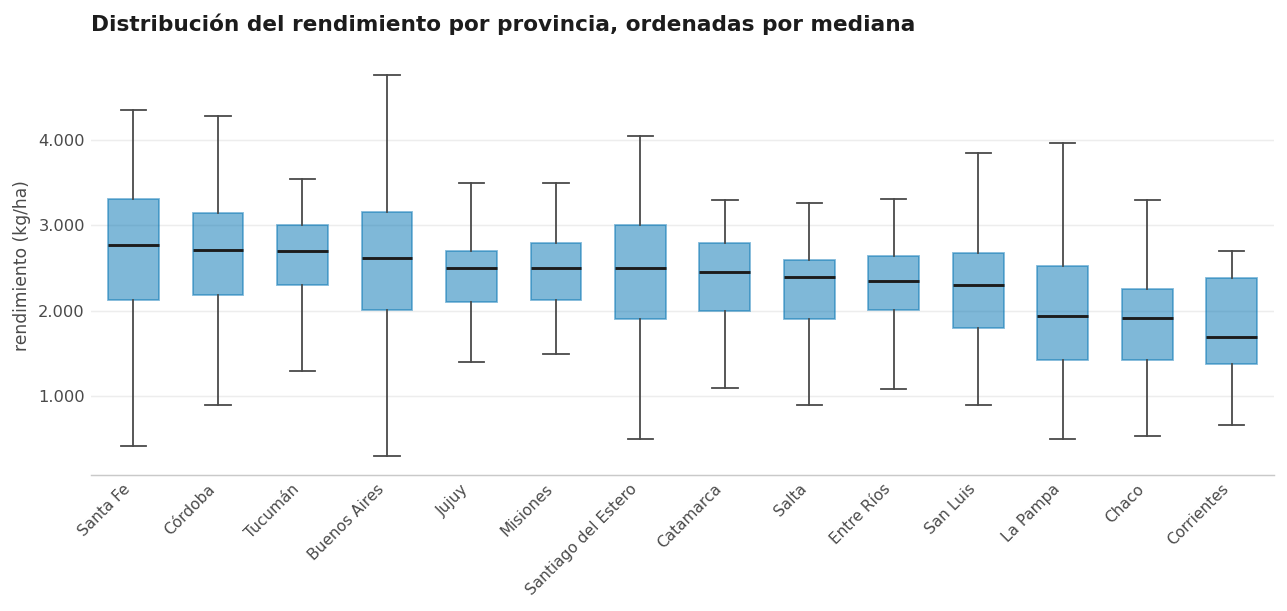

Coeficiente de variación (desvío / media, %):
  más volátil : La Pampa (39%)
  más estable : Jujuy (19%)


In [18]:
orden = d.groupby("provincia").rendimiento_kgxha.median().sort_values(ascending=False).index
datos = [d.loc[d.provincia == p, "rendimiento_kgxha"].values for p in orden]

fig, ax = plt.subplots(figsize=(10, 4.8))
bp = ax.boxplot(datos, patch_artist=True, widths=.6, showfliers=False,
                 medianprops={"color": TINTA, "linewidth": 1.6})
for box in bp["boxes"]:
    box.set(facecolor=AZUL, alpha=.5, edgecolor=AZUL, linewidth=1)
for el in ("whiskers", "caps"):
    for line in bp[el]: line.set(color=TINTA2, linewidth=1)

ax.set_xticks(range(1, len(orden) + 1))
ax.set_xticklabels(orden, rotation=45, ha="right", fontsize=8.5)
ax.set_ylabel("rendimiento (kg/ha)")
ax.set_title("Distribución del rendimiento por provincia, ordenadas por mediana")
limpiar(ax)
plt.tight_layout(); plt.show()

cv = d.groupby("provincia").rendimiento_kgxha.agg(lambda s: s.std() / s.mean() * 100)
print("Coeficiente de variación (desvío / media, %):")
print(f"  más volátil : {cv.idxmax()} ({cv.max():.0f}%)")
print(f"  más estable : {cv.idxmin()} ({cv.min():.0f}%)")

El orden por mediana **no coincide** con el orden por volatilidad. La Pampa
tiene una mediana media-baja pero es la provincia más volátil (CV ≈ 39%): la
caja es ancha y los años malos son muy malos. Jujuy y Tucumán, en cambio,
combinan buen rendimiento con la menor dispersión relativa. Para una prima de
seguro esto importa tanto como el nivel: **la volatilidad histórica de la zona
es, en sí misma, una variable a modelar**, no solo el rendimiento esperado.

### 3.9 La frontera agrícola se mueve

La única variable no climática que sobrevivió al filtro de leakage es la
superficie sembrada (sección 2.7). Antes de usarla como predictor conviene
mirarla: si el área sembrada creció fuerte durante el panel, parte de la
tendencia de la sección 3.1 puede ser expansión hacia zonas nuevas y no solo
mejora genética.

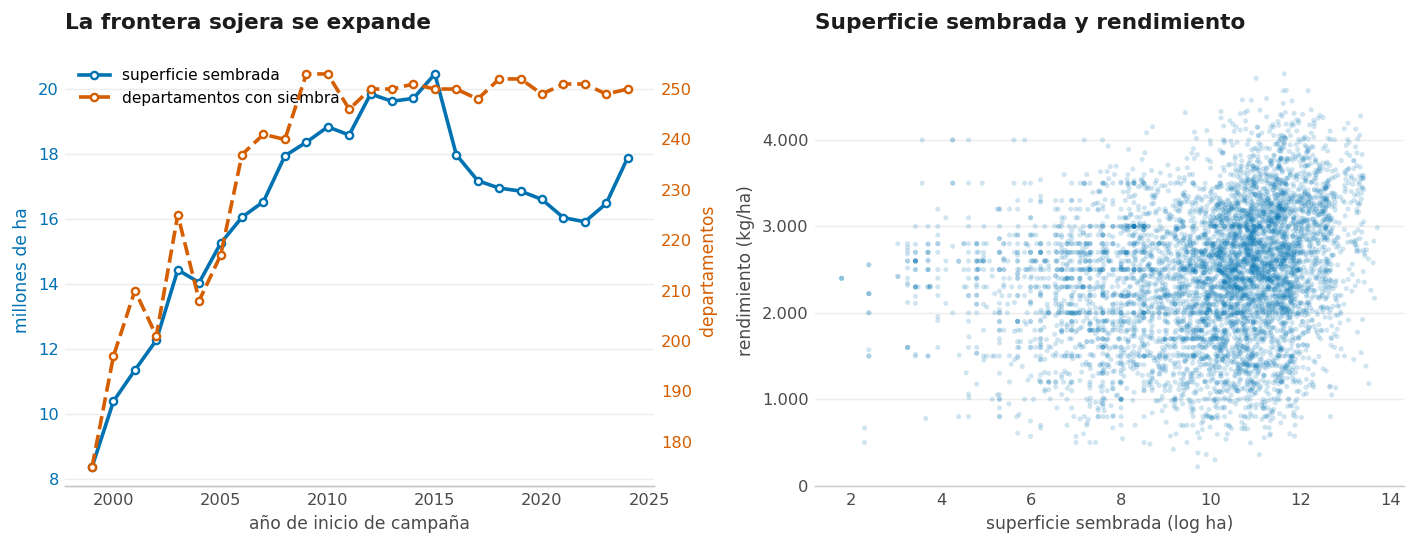

Superficie sembrada: 8.4 -> 17.9 millones de ha (+114%).
Departamentos con soja: 175 -> 250.
Correlación superficie sembrada (log) - rendimiento: r=0.21


In [19]:
por_anio = d.groupby("anio").agg(sup=("superficie_sembrada_ha", "sum"),
                                  deptos=("departamento_id", "nunique"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))

l1, = a1.plot(por_anio.index, por_anio.sup / 1e6, color=AZUL, lw=2, marker="o", ms=4,
              markerfacecolor="white", markeredgewidth=1.3, label="superficie sembrada")
a1.set_ylabel("millones de ha", color=AZUL)
a1.tick_params(axis="y", colors=AZUL, length=0)
a1b = a1.twinx()
l2, = a1b.plot(por_anio.index, por_anio.deptos, color=NARANJA, lw=2, ls="--",
               marker="o", ms=4, markerfacecolor="white", markeredgewidth=1.3,
               label="departamentos con siembra")
a1b.set_ylabel("departamentos", color=NARANJA)
a1b.tick_params(axis="y", colors=NARANJA, length=0)
a1b.grid(False)
a1.set_title("La frontera sojera se expande")
a1.set_xlabel("año de inicio de campaña")
a1.legend(handles=[l1, l2], loc="upper left", fontsize=8.5)
limpiar(a1, y=False)

a2.scatter(d.sup_sembrada_log, d.rendimiento_kgxha, s=8, color=AZUL, alpha=.18, edgecolor="none")
a2.set_xlabel("superficie sembrada (log ha)"); a2.set_ylabel("rendimiento (kg/ha)")
a2.set_title("Superficie sembrada y rendimiento")
limpiar(a2)
plt.tight_layout(); plt.show()

crecimiento = por_anio.sup.iloc[-1] / por_anio.sup.iloc[0] - 1
print(f"Superficie sembrada: {por_anio.sup.iloc[0]/1e6:.1f} -> {por_anio.sup.iloc[-1]/1e6:.1f} "
      f"millones de ha ({crecimiento*100:+.0f}%).")
print(f"Departamentos con soja: {por_anio.deptos.iloc[0]} -> {por_anio.deptos.iloc[-1]}.")
print(f"Correlación superficie sembrada (log) - rendimiento: "
      f"r={d.sup_sembrada_log.corr(d.rendimiento_kgxha):.2f}")

La superficie sembrada creció 114% y el número de departamentos con soja pasó
de 175 a 250: **la soja se expandió hacia el margen**, no solo se intensificó
donde ya estaba. Eso significa que en la tendencia creciente de la sección 3.1
conviven dos efectos que el modelo tiene que poder separar: mejora genética en
el núcleo histórico, y entrada de zonas nuevas que arrancan con rendimientos
más bajos. La correlación entre superficie sembrada y rendimiento es débil
(r ≈ 0,21) y positiva, no negativa — el área creció, pero no diluyó el
promedio; lo esperable si la expansión sigue eligiendo, dentro de cada zona
nueva, los departamentos relativamente mejores.

### 3.10 La normal climática, ¿sigue siendo normal?

La sección 2.7 fijó la normal contra la que se calculan las anomalías usando
solo campañas hasta 2018, para no filtrar el período de evaluación. Eso resuelve
el leakage, pero abre otra pregunta: si el clima tiene tendencia, esa normal
**envejece** con cada campaña que pasa, y las anomalías post-2018 dejan de
significar "raro" para empezar a significar, en parte, "más reciente".

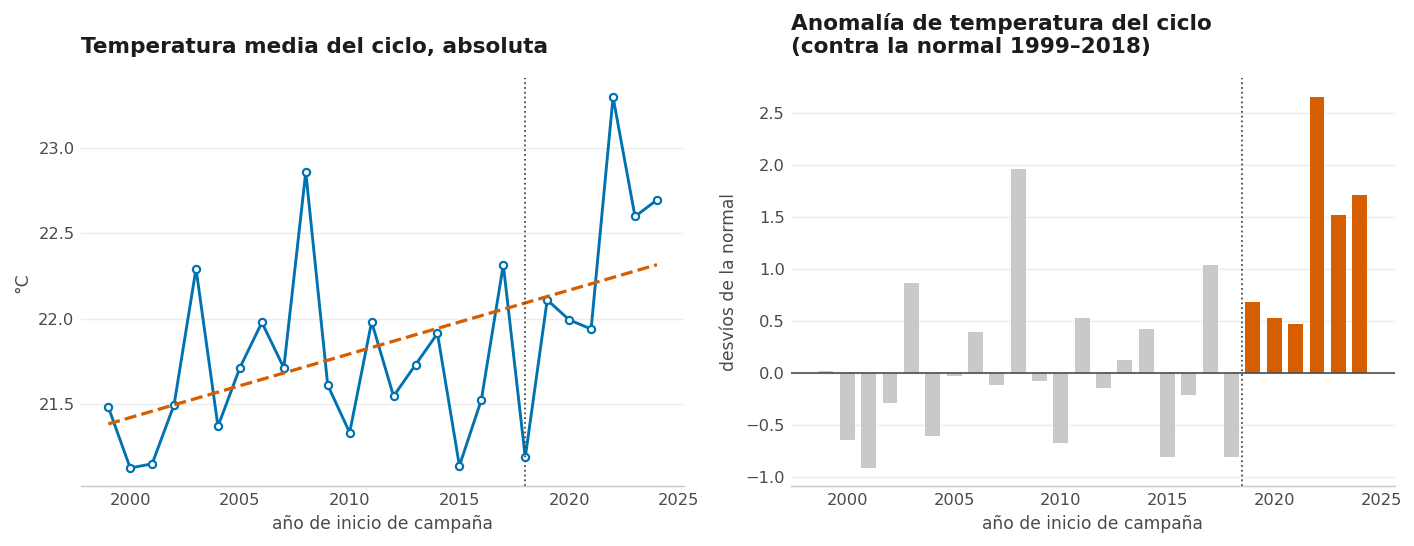

Tendencia lineal 1999–2024: +0.37 °C por década (recta punteada, panel izquierdo).
Anomalía media de temperatura del ciclo, pre-2018 (control): +0.00 desvíos.
Anomalía media de temperatura del ciclo, 2019–2024 (evaluación): +1.26 desvíos.


In [20]:
tmed_anio = d.groupby("anio").ciclo_tmed.mean()
anom_anio = d.groupby("anio").anom_ciclo_tmed.mean()
pend, orig = np.polyfit(tmed_anio.index, tmed_anio.values, 1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))

a1.plot(tmed_anio.index, tmed_anio.values, color=AZUL, lw=1.6, marker="o", ms=4,
        markerfacecolor="white", markeredgewidth=1.2)
a1.plot(tmed_anio.index, pend * tmed_anio.index + orig, color=NARANJA, lw=1.8, ls="--")
a1.axvline(2018, color=TINTA2, lw=1, ls=":")
a1.set_title("Temperatura media del ciclo, absoluta")
a1.set_ylabel("°C"); a1.set_xlabel("año de inicio de campaña")
limpiar(a1, y=False)

col = [TENUE if a <= 2018 else NARANJA for a in anom_anio.index]
a2.bar(anom_anio.index, anom_anio.values, color=col, width=.7)
a2.axhline(0, color=TINTA2, lw=.9)
a2.axvline(2018.5, color=TINTA2, lw=1, ls=":")
a2.set_title("Anomalía de temperatura del ciclo\n(contra la normal 1999–2018)")
a2.set_ylabel("desvíos de la normal"); a2.set_xlabel("año de inicio de campaña")
limpiar(a2, y=False)
plt.tight_layout(); plt.show()

pre = anom_anio[anom_anio.index <= 2018].mean()
post = anom_anio[anom_anio.index > 2018].mean()
print(f"Tendencia lineal 1999–2024: {pend*10:+.2f} °C por década (recta punteada, panel izquierdo).")
print(f"Anomalía media de temperatura del ciclo, pre-2018 (control): {pre:+.2f} desvíos.")
print(f"Anomalía media de temperatura del ciclo, 2019–2024 (evaluación): {post:+.2f} desvíos.")

La respuesta es sí, y con margen. La temperatura media del ciclo sube
≈0,37 °C por década (p < 0,01). Como control, la anomalía promedio **antes**
de 2018 da ≈0 por construcción — la normal se ajusta a sí misma. Pero en el
período de evaluación (2019–2024) la anomalía promedio es **+1,26 desvíos**:
un campo cualquiera hoy corre, en promedio, más de un desvío estándar "más
caliente que lo normal" — no porque el año sea raro, sino porque **la normal
quedó vieja**.

Esto no invalida la sección 4 (evita el leakage, que era el riesgo mayor), pero
sí matiza el "se reentrena cada año" de la sección 1: **reentrenar con datos
nuevos no alcanza si la normal contra la que se miden las anomalías no se
recalcula también**, cada tres o cinco años. Si no, la anomalía deja de separar
"año raro" de "año reciente" y el modelo puede terminar aprendiendo una
tendencia temporal disfrazada de señal climática.

---
## 4. Viabilidad del modelo

Partición **temporal**: se entrena con campañas hasta 2019/20 y se evalúa sobre
2020/21 – 2024/25. Nunca se entrena con el futuro.

Se comparan dos cosas contra el baseline: el **modelo de producción**, que usa
solo las cuatro ventanas cerradas al 10 de febrero, y un **modelo exploratorio**
con todas las ventanas, cuyo único fin es medir en la sección 4.1 qué etapas del
cultivo cargan la información.

**Sobre el uso del set de test.** Esta sección y el Anexo A lo evalúan varias
veces —modelo de producción, exploratorio, tres momentos de decisión, ENSO— sin
un split de validación intermedio. Es deliberado y acota lo que se puede afirmar:
acá se mide **si hay señal**, no se selecciona un modelo. Los números son una
cota optimista de lo que rendiría un modelo elegido con este procedimiento. La
comparación sistemática con validación temporal anidada queda para el examen
final.

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor

TEST = [2020, 2021, 2022, 2023, 2024]
tr, te = d[~d.anio.isin(TEST)], d[d.anio.isin(TEST)]
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

# Baseline: promedio histórico del departamento
media_dep = tr.groupby("departamento_id").rendimiento_kgxha.mean()
p_base = te.departamento_id.map(media_dep).fillna(tr.rendimiento_kgxha.mean()).values
r_base = rmse(te.rendimiento_kgxha, p_base)

def features_de(ventanas):
    out = []
    for v in ventanas:
        out += [c for c in d.columns
                if c.startswith(v + "_") or c.startswith("anom_" + v + "_")]
    return [c for c in out if d[c].nunique() > 1]

VENT_FEB = ["barbecho", "siembra", "vegetativo", "floracion"]
usar_feb = estruct + features_de(VENT_FEB)                    # modelo de PRODUCCIÓN
usar = [c for c in clima_abs + clima_ano + estruct if d[c].nunique() > 1]   # exploratorio

ajustar = lambda cols: HistGradientBoostingRegressor(
    random_state=0, max_iter=400, learning_rate=.06).fit(tr[cols], tr.rendimiento_kgxha)

mod_feb = ajustar(usar_feb); p_feb = mod_feb.predict(te[usar_feb])
mod     = ajustar(usar);     p_mod = mod.predict(te[usar])
r_feb, r_mod = rmse(te.rendimiento_kgxha, p_feb), rmse(te.rendimiento_kgxha, p_mod)

print(f"train {len(tr):,} obs | test {len(te):,} obs\n")
print(f"  Baseline (promedio del depto)              RMSE = {r_base:.0f} kg/ha")
print(f"  Modelo de producción (10 feb, {len(usar_feb):3d} feat)  RMSE = {r_feb:.0f} kg/ha"
      f"   ({(1 - r_feb/r_base)*100:+.1f}%)")
print(f"  Exploratorio, todas las ventanas ({len(usar)} feat) RMSE = {r_mod:.0f} kg/ha"
      f"   ({(1 - r_mod/r_base)*100:+.1f}%)")
print("\n  El exploratorio NO es utilizable en producción: usa llenado y cosecha,")
print("  que al 10 de febrero todavía no ocurrieron. Solo sirve para la sección 4.1.")

train 4,906 obs | test 1,250 obs

  Baseline (promedio del depto)              RMSE = 665 kg/ha
  Modelo de producción (10 feb,  98 feat)  RMSE = 584 kg/ha   (+12.1%)
  Exploratorio, todas las ventanas (170 feat) RMSE = 563 kg/ha   (+15.4%)

  El exploratorio NO es utilizable en producción: usa llenado y cosecha,
  que al 10 de febrero todavía no ocurrieron. Solo sirve para la sección 4.1.


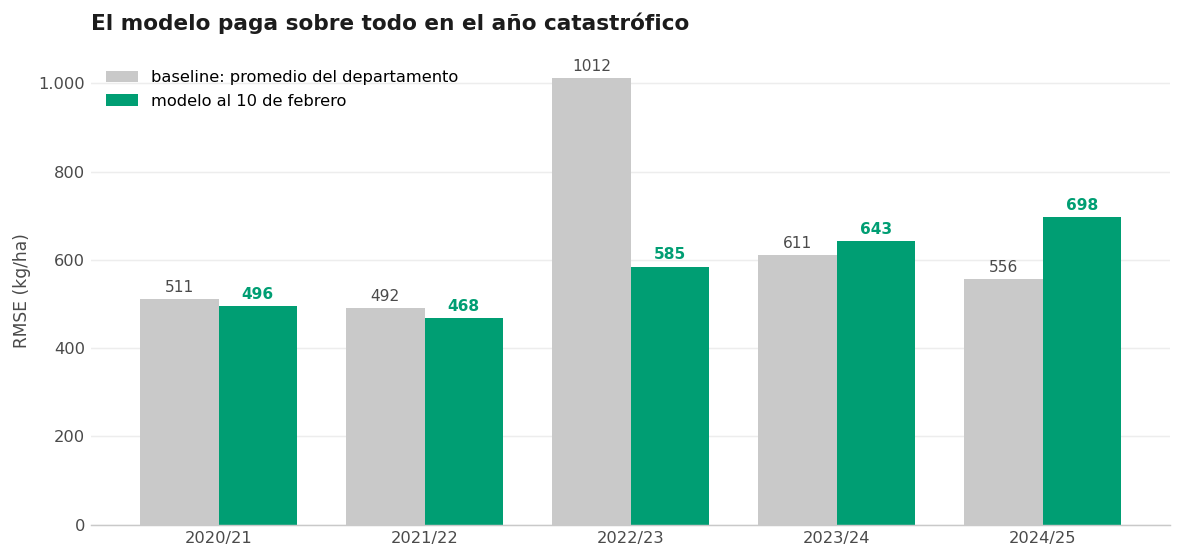

En 2022/23 el error cae de 1012 a 585 kg/ha: 42% menos.


In [22]:
te2 = te.copy(); te2["pred_base"] = p_base; te2["pred_feb"] = p_feb
por = te2.groupby("anio").apply(lambda g: pd.Series({
    "real": g.rendimiento_kgxha.mean(),
    "rmse_base": rmse(g.rendimiento_kgxha, g["pred_base"]),
    "rmse_feb": rmse(g.rendimiento_kgxha, g["pred_feb"])}))

fig, ax = plt.subplots(figsize=(9.2, 4.4))
x = np.arange(len(por)); w = .38
ax.bar(x - w/2, por.rmse_base, w, color=TENUE, label="baseline: promedio del departamento")
ax.bar(x + w/2, por.rmse_feb, w, color=VERDE, label="modelo al 10 de febrero")
for i, (b, m) in enumerate(zip(por.rmse_base, por.rmse_feb)):
    ax.text(i - w/2, b + 16, f"{b:.0f}", ha="center", fontsize=8.5, color=TINTA2)
    ax.text(i + w/2, m + 16, f"{m:.0f}", ha="center", fontsize=8.5, color=VERDE, weight="600")
ax.set_xticks(x); ax.set_xticklabels([f"{a}/{str(a+1)[2:]}" for a in por.index])
ax.set_ylabel("RMSE (kg/ha)")
ax.set_title("El modelo paga sobre todo en el año catastrófico")
ax.legend(loc="upper left"); limpiar(ax)
plt.tight_layout(); plt.show()

r22 = por.loc[2022]
print(f"En 2022/23 el error cae de {r22.rmse_base:.0f} a {r22.rmse_feb:.0f} kg/ha: "
      f"{(1 - r22.rmse_feb/r22.rmse_base)*100:.0f}% menos.")

El resultado tiene la forma que el caso de negocio necesita. En campañas normales
el modelo empata con el baseline o lo mejora poco. **En 2022/23 le recorta el 42% del
error.** Para una aseguradora ahí está el dinero: el año en que hay
que pagar es justamente el que el promedio histórico no ve venir.

### 4.1 Qué mira el modelo

Que el clima mejore el error no dice todavía *cuál* clima. Se mide la
importancia por permutación sobre el set de test: cuánto empeora el RMSE al
barajar al azar cada feature, manteniendo el resto intacto.

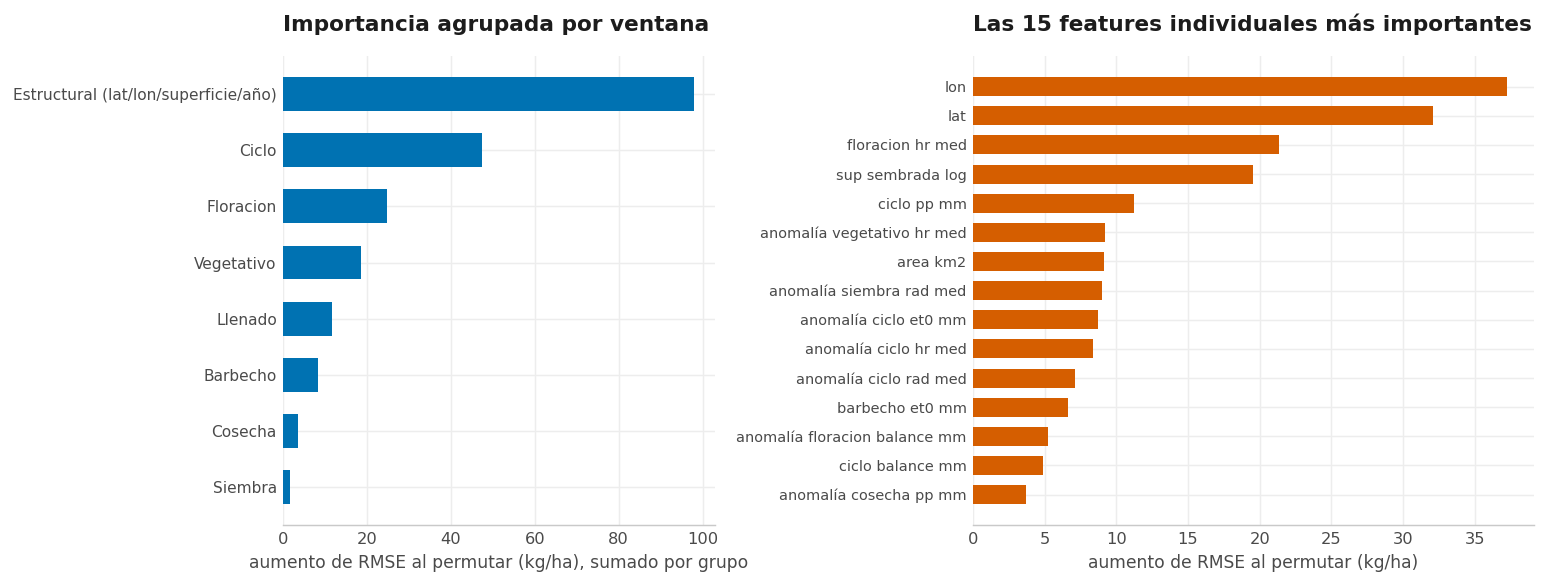

Estructural (lat/lon/superficie/año)    98.0
Ciclo                                   47.5
Floracion                               24.8
Vegetativo                              18.6
Llenado                                 11.8
Barbecho                                 8.3
Cosecha                                  3.5
Siembra                                  1.5


In [23]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(mod, te[usar], te.rendimiento_kgxha,
                                scoring="neg_root_mean_squared_error",
                                n_repeats=8, random_state=0, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=usar)  # aumento de RMSE (kg/ha) al permutar

def ventana_de(col):
    core = col[len("anom_"):] if col.startswith("anom_") else col
    for v in VENTANAS:
        if core.startswith(v + "_"): return v.capitalize()
    return "Estructural (lat/lon/superficie/año)"

grp = imp.groupby([ventana_de(c) for c in imp.index]).sum().sort_values()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})

a1.barh(range(len(grp)), grp.values, color=AZUL, height=.6)
a1.set_yticks(range(len(grp))); a1.set_yticklabels(grp.index, fontsize=8.5)
a1.set_xlabel("aumento de RMSE al permutar (kg/ha), sumado por grupo")
a1.set_title("Importancia agrupada por ventana")
a1.grid(True, axis="x"); a1.tick_params(length=0)

top15 = imp.sort_values(ascending=False).head(15).sort_values()
a2.barh(range(len(top15)), top15.values, color=NARANJA, height=.65)
a2.set_yticks(range(len(top15)))
a2.set_yticklabels([t.replace("anom_", "anomalía ").replace("_", " ") for t in top15.index],
                   fontsize=8)
a2.set_xlabel("aumento de RMSE al permutar (kg/ha)")
a2.set_title("Las 15 features individuales más importantes")
a2.grid(True, axis="x"); a2.tick_params(length=0)
plt.tight_layout(); plt.show()

print(grp.sort_values(ascending=False).round(1).to_string())

Dos lecturas. La primera confirma la sección 3.3: el grupo **estructural**
(latitud, longitud, superficie, año) es, de lejos, el más importante —
consistente con que el "lugar" explique 37% de la varianza total. La segunda
matiza la sección 2.6: dentro del clima, **floración y vegetativo pesan más
que llenado**, que era la ventana señalada a priori como la que define el
rendimiento. No es necesariamente que el prior agronómico esté mal: llenado
comparte información con floración y con el ciclo completo (sección 3.7), así
que parte de su efecto real puede estar contabilizado ahí. La importancia por
permutación es una guía, no una prueba causal, precisamente por la
multicolinealidad que ya se documentó.

### 4.2 ¿Por qué febrero y no antes?

La objeción natural es que a la aseguradora le convendría saberlo en noviembre,
al tarifar. Para verificar si eso es posible se entrena un modelo por cada
momento de decisión, usando **solo las ventanas cerradas a esa fecha**. Mismo
algoritmo, misma partición, misma métrica.

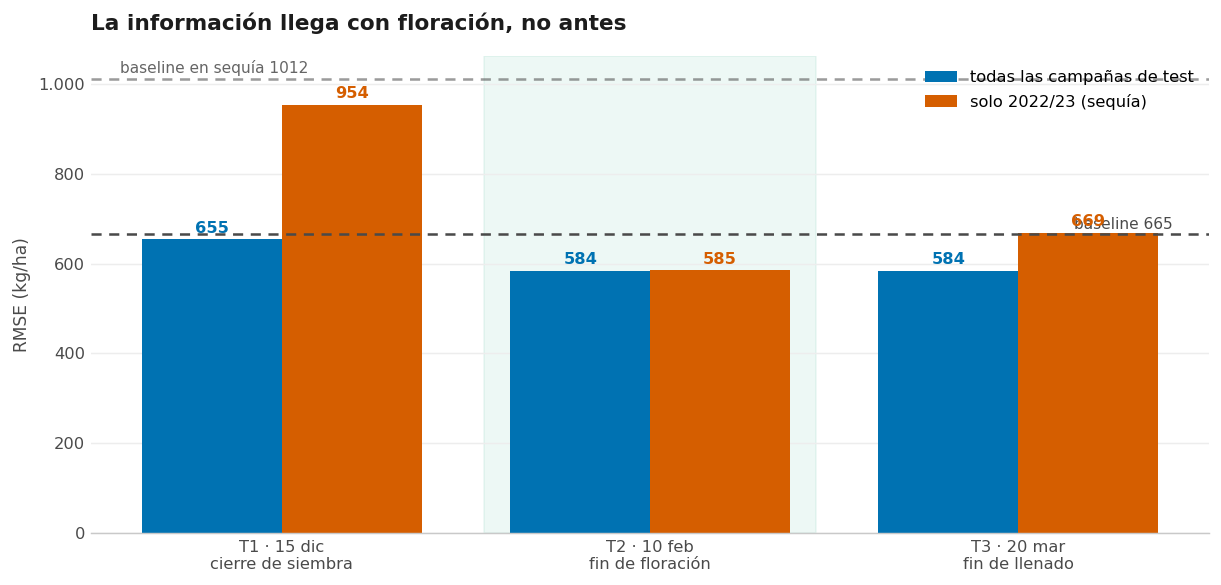

                      momento  features  rmse  rmse_sequia  mejora_pct
T1 · 15 dic cierre de siembra        53 654.8        953.6         1.6
 T2 · 10 feb fin de floración        98 584.3        584.9        12.1
   T3 · 20 mar fin de llenado       122 584.3        668.8        12.2


In [24]:
MOMENTOS_DEF = [
    ("T1 · 15 dic\ncierre de siembra", ["barbecho", "siembra"]),
    ("T2 · 10 feb\nfin de floración",  VENT_FEB),
    ("T3 · 20 mar\nfin de llenado",    VENT_FEB + ["llenado"]),
]

# Guarda: ninguna ventana posterior al corte puede entrar como feature.
# cosecha va del 21 de marzo al 10 de mayo; ciclo, de octubre a abril.
PROHIBIDAS = ("cosecha_", "anom_cosecha_", "ciclo_", "anom_ciclo_")
for _n, _vs in MOMENTOS_DEF:
    assert not [c for c in features_de(_vs) if c.startswith(PROHIBIDAS)], _n

seq = (te.anio == 2022).values
r_base_seq = rmse(te.rendimiento_kgxha[seq], p_base[seq])

filas = []
for nombre, vs in MOMENTOS_DEF:
    cs = estruct + features_de(vs)
    p = ajustar(cs).predict(te[cs])
    filas.append({"momento": nombre, "features": len(cs),
                  "rmse": rmse(te.rendimiento_kgxha, p),
                  "rmse_sequia": rmse(te.rendimiento_kgxha[seq], p[seq])})
mom = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(mom)); w = .38
ax.bar(x - w/2, mom.rmse, w, color=AZUL, label="todas las campañas de test")
ax.bar(x + w/2, mom.rmse_sequia, w, color=NARANJA, label="solo 2022/23 (sequía)")
ax.axhline(r_base, color=TINTA2, lw=1.4, ls=(0, (4, 3)))
ax.text(2.42, r_base + 12, f"baseline {r_base:.0f}", ha="right", fontsize=8.5, color=TINTA2)
ax.axhline(r_base_seq, color=TINTA2, lw=1.4, ls=(0, (4, 3)), alpha=.55)
ax.text(-.44, r_base_seq + 12, f"baseline en sequía {r_base_seq:.0f}",
        ha="left", fontsize=8.5, color=TINTA2, alpha=.85)
for i, r in mom.iterrows():
    ax.text(i - w/2, r.rmse + 14, f"{r.rmse:.0f}", ha="center", fontsize=9, color=AZUL, weight="600")
    ax.text(i + w/2, r.rmse_sequia + 14, f"{r.rmse_sequia:.0f}", ha="center",
            fontsize=9, color=NARANJA, weight="600")
ax.axvspan(.55, 1.45, color=VERDE, alpha=.07, zorder=0)
ax.set_xticks(x); ax.set_xticklabels(mom.momento, fontsize=9)
ax.set_ylabel("RMSE (kg/ha)")
ax.set_title("La información llega con floración, no antes")
ax.legend(loc="upper right"); limpiar(ax)
plt.tight_layout(); plt.show()

print(mom.assign(momento=mom.momento.str.replace("\n", " ", regex=False),
                 mejora_pct=(1 - mom.rmse / r_base) * 100).round(1).to_string(index=False))

**En diciembre el modelo no sirve.** Con solo barbecho y siembra cerradas mejora
un 1,6% sobre el promedio histórico, y en la sequía apenas baja de 1012 a 954
kg/ha. Es coherente con la agronomía —en diciembre no ocurrió todavía nada de lo
que define el rendimiento— y con la sección 3.3, donde la porción grande de la
varianza era el clima local del verano.

Entre diciembre y febrero el error cae de 655 a 584, y en la sequía se desploma
de 954 a 585. **Todo el valor aparece con floración.**

Y después de floración no aparece nada más: sumar la ventana de llenado deja el
error general en el mismo nivel que febrero y en la campaña de sequía lo
**empeora**. Esperar un mes más no compra precisión, solo cuesta anticipación.
Por eso la corrida principal es la del 10 de febrero, sin refinamiento posterior.

> **Corrección.** Una versión anterior de esta comparación daba 565 kg/ha para el
> momento de marzo. Ese cálculo incorporaba las ventanas `cosecha` (21 mar – 10
> may) y `ciclo` (oct – abr), las dos posteriores a su propia fecha de corte: la
> mejora era fuga de información, no señal. El `assert` de la celda anterior
> impide que vuelva a ocurrir.

En el **Anexo A** se documenta el intento de adelantar la predicción a noviembre
incorporando el índice ENSO, y por qué no funcionó.

---
## 5. Conclusiones

**Sobre el dataset**

1. **Se sostiene y es reproducible.** 6.156 observaciones de 255 departamentos en
   26 campañas, sin faltantes ni duplicados, construido desde dos fuentes
   públicas y programáticas: se regenera cada año corriendo cuatro scripts.

2. **El leakage estaba y se removió.** `rendimiento` se reconstruye exactamente
   desde `produccion` y `superficie_cosechada` (error mediano 0,09 kg/ha), así
   que ambas quedaron fuera. La normal climática se calcula solo con campañas
   ≤ 2018. Y el modelo de producción usa únicamente las cuatro ventanas cerradas
   al 10 de febrero.

3. **El panel es desbalanceado por diseño**, no por error: la frontera sojera se
   expandió durante el período (sección 3.9). Filtrar por completitud sesgaría el
   panel hacia las zonas consolidadas.

**Sobre el fenómeno**

4. **Saber dónde está el campo explica poco.** El departamento da cuenta del 37%
   de la varianza; el 63% restante depende del año, y la porción mayor (40%) es
   la interacción departamento × campaña — el clima local de ese lugar ese
   verano. Esto justificó el enriquecimiento climático *antes* de entrenar nada.

5. **La señal es multivariada, no de una variable estrella.** Ninguna feature
   supera |r| = 0,40 y muchas están fuertemente correlacionadas entre sí
   (sección 3.7), por lo que las importancias son orientativas y no causales.

6. **La normal de referencia envejece.** El ciclo se calienta a ~0,37 °C por
   década y la anomalía media del test ya corre en +1,26 desvíos (sección 3.10).
   Producción necesita una política de recalibración, no solo de reentrenamiento.

**Sobre el caso de negocio**

7. **El modelo de febrero mejora 12% sobre el baseline y 42% en la campaña
   de sequía**, usando solo información disponible a esa fecha. En unidades del
   negocio: en 2022/23 recorta la sobrestimación de producción de 15,0 a 6,8 Mt.

8. **El momento importa tanto como el modelo.** Adelantar la corrida a diciembre
   la vuelve inútil (+1,6%), y ni el índice ENSO lo cambia (Anexo A). El valor
   aparece con floración y no antes — un límite del fenómeno, no del método.

9. **Esto es una herramienta de gestión de reservas, no de tarifación.** Es la
   conclusión que ordena el trabajo: define para qué decisión sirve el modelo y,
   sobre todo, para cuál no.

**Qué falta para el examen final**

Suelo y agua útil por departamento, hoy la principal ausencia; NDVI satelital
como termómetro del cultivo en tiempo real, que sí estaría disponible en febrero;
comparación sistemática de modelos con validación temporal anidada; y sobre todo
**intervalos de predicción**, porque una aseguradora que solo recibe el valor
esperado no puede calcular capital de solvencia.

---
## Anexo A · ¿Se puede adelantar la predicción a noviembre?

**La hipótesis.** El caso de negocio sería más valioso si el modelo sirviera
también para tarifar, antes de la siembra. El único predictor conocido del verano
que ya está publicado en noviembre es el **ENSO**: la fase de El Niño/La Niña,
medida por el Oceanic Niño Index de NOAA. La conexión Niña → verano seco en la
Pampa húmeda es una de las teleconexiones mejor documentadas de la climatología
argentina, y las tres sequías del panel (2008/09, 2017/18, 2022/23) ocurrieron en
años de ONI negativo o neutro-negativo.

Se descargó el ONI (`05_descargar_enso.py`) y se construyeron seis features con
fecha de corte respetada: ONI de septiembre, octubre y noviembre, el promedio del
trimestre SON, la tendencia agosto-noviembre y la intensidad de la Niña. Todas
publicadas antes del 15 de diciembre.

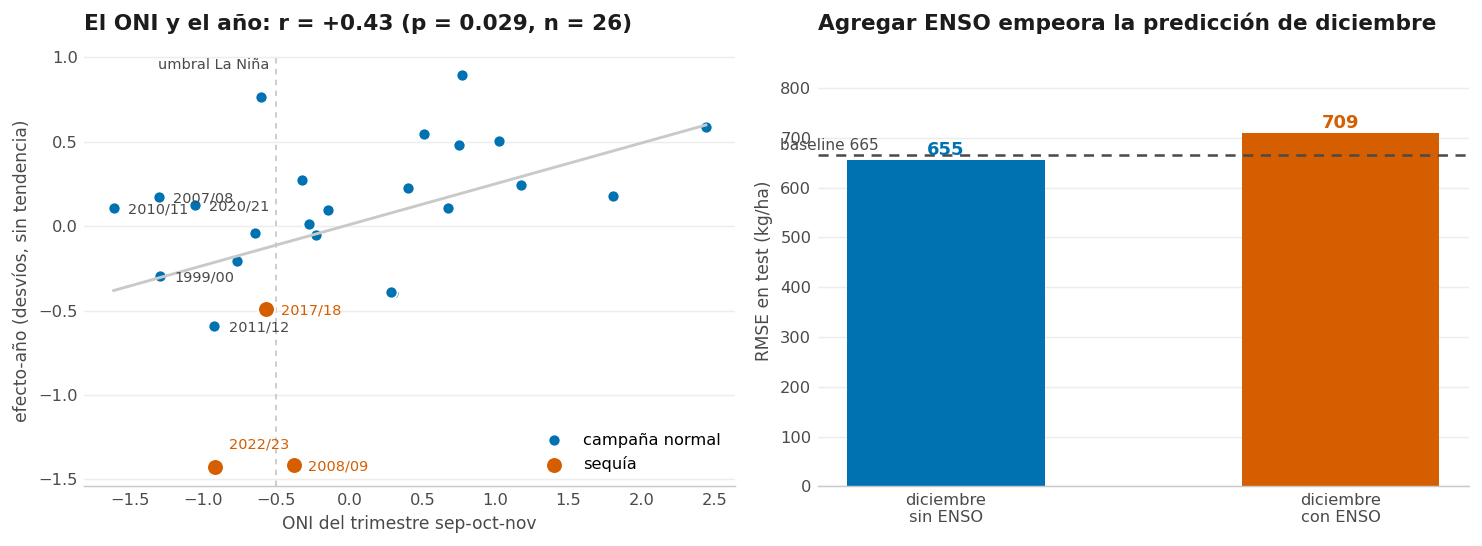

Correlación ONI vs efecto-año (sin tendencia): r = +0.429, p = 0.029
  -> el ONI explica el 18% del efecto-año, que a su vez es
     parte de la varianza total.

  diciembre sin ENSO       RMSE = 655  (+1.6% vs baseline)
  diciembre con ENSO       RMSE = 709  (-6.5% vs baseline)


In [25]:
from scipy import stats

oni = pd.read_csv("../data/raw/oni.csv")
dn = d.merge(oni, on="anio", how="left")

# ── Prueba 1: ¿el ONI explica el efecto-año del rendimiento? ─────────────────
dn["z"] = dn.groupby("departamento_id").rendimiento_kgxha.transform(
    lambda s: (s - s.mean()) / s.std())
ef = dn.groupby("anio").agg(z=("z", "mean"), oni=("oni_son", "first")).reset_index()
ef["z_sin_tend"] = ef.z - np.poly1d(np.polyfit(ef.anio, ef.z, 1))(ef.anio)
r_p, p_p = stats.pearsonr(ef.oni, ef.z_sin_tend)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
SEQ_ANIOS = (2008, 2017, 2022)
es_seq = ef.anio.isin(SEQ_ANIOS)
a1.scatter(ef.oni[~es_seq], ef.z_sin_tend[~es_seq], s=45, color=AZUL,
           edgecolor="white", linewidth=1, label="campaña normal")
a1.scatter(ef.oni[es_seq], ef.z_sin_tend[es_seq], s=90, color=NARANJA,
           edgecolor="white", linewidth=1.2, zorder=5, label="sequía")
for r in ef[es_seq].itertuples():
    dx, dy = (8, 10) if r.z_sin_tend < -1 and r.oni < -.7 else (8, -3)
    a1.annotate(f"{r.anio}/{str(r.anio+1)[2:]}", (r.oni, r.z_sin_tend),
                textcoords="offset points", xytext=(dx, dy), fontsize=8, color=NARANJA)
for r in ef[(ef.oni < -.9) & ~es_seq].itertuples():
    a1.annotate(f"{r.anio}/{str(r.anio+1)[2:]}", (r.oni, r.z_sin_tend),
                textcoords="offset points", xytext=(8, -3), fontsize=8, color=TINTA2)
xs = np.linspace(ef.oni.min(), ef.oni.max(), 50)
a1.plot(xs, np.poly1d(np.polyfit(ef.oni, ef.z_sin_tend, 1))(xs), color=TENUE, lw=1.6)
a1.axvline(-.5, color=TENUE, lw=1, ls=(0, (3, 3)))
a1.text(-.55, a1.get_ylim()[1] * .92, "umbral La Niña", ha="right", fontsize=8, color=TINTA2)
a1.set_xlabel("ONI del trimestre sep-oct-nov"); a1.set_ylabel("efecto-año (desvíos, sin tendencia)")
a1.set_title(f"El ONI y el año: r = {r_p:+.2f} (p = {p_p:.3f}, n = {len(ef)})")
a1.legend(loc="lower right"); limpiar(a1, y=False)

# ── Prueba 2: ¿mejora la predicción de diciembre? ────────────────────────────
ENSO = ["oni_son", "nina_intensidad", "oni_tendencia"]
trn, ten = dn[~dn.anio.isin(TEST)], dn[dn.anio.isin(TEST)]
T1F = [c for c in estruct + features_de(["barbecho", "siembra"])]
comp = {}
for nom, cs in [("diciembre\nsin ENSO", T1F), ("diciembre\ncon ENSO", T1F + ENSO)]:
    m = HistGradientBoostingRegressor(random_state=0, max_iter=400,
                                      learning_rate=.06).fit(trn[cs], trn.rendimiento_kgxha)
    comp[nom] = rmse(ten.rendimiento_kgxha, m.predict(ten[cs]))

a2.bar(range(len(comp)), list(comp.values()), color=[AZUL, NARANJA], width=.5)
a2.axhline(r_base, color=TINTA2, lw=1.4, ls=(0, (4, 3)))
a2.text(-.42, r_base + 10, f"baseline {r_base:.0f}", ha="left", fontsize=8.5, color=TINTA2)
for i, v in enumerate(comp.values()):
    a2.text(i, v + 10, f"{v:.0f}", ha="center", fontsize=10, weight="600",
            color=AZUL if i == 0 else NARANJA)
a2.set_xticks(range(len(comp))); a2.set_xticklabels(list(comp), fontsize=9)
a2.set_ylabel("RMSE en test (kg/ha)"); a2.set_ylim(0, max(comp.values()) * 1.22)
a2.set_title("Agregar ENSO empeora la predicción de diciembre")
limpiar(a2)
plt.tight_layout(); plt.show()

print(f"Correlación ONI vs efecto-año (sin tendencia): r = {r_p:+.3f}, p = {p_p:.3f}")
print(f"  -> el ONI explica el {r_p**2*100:.0f}% del efecto-año, que a su vez es")
print(f"     parte de la varianza total.\n")
for k, v in comp.items():
    print(f"  {k.replace(chr(10), ' '):24s} RMSE = {v:.0f}  ({(1-v/r_base)*100:+.1f}% vs baseline)")

**Por qué falla.** La relación es estadísticamente significativa pero débil: el
ONI explica cerca del 18% del efecto-año, y el efecto-año es apenas una parte de
la varianza total. Los contraejemplos lo muestran mejor que el coeficiente:
**2010/11 tuvo la Niña más intensa del panel (ONI −1,61) con rendimientos
normales**, y 2016/17 fue Niña y resultó el segundo mejor año. En el otro
sentido, 2008/09 —la segunda peor campaña— quedó clasificada como neutral.

Con solo 21 campañas de entrenamiento, un predictor que toma **un valor por año**
tiene demasiado poco con qué generalizar: el modelo lo usa para memorizar años
concretos, y en test empeora.

También se probó reformular el problema como clasificación —predecir la
probabilidad de que el rendimiento caiga bajo el 70% de la media zonal, que es lo
que un seguro indexado realmente necesita. El AUC global de 0,671 parece
alentador, pero desagregado por campaña da 0,25 / 0,39 / 0,59 / 0,58 / 0,26:
**dentro de cada año el modelo ordena los departamentos peor que el azar**, y el
número global solo refleja que 2022/23 fue malo en promedio.

**Conclusión del anexo:** la tarifación pre-siembra no se puede mejorar con los
datos públicos disponibles. No es una limitación del algoritmo sino del
fenómeno — en noviembre la información sobre el verano todavía no existe. Esto
es lo que fija la corrida del modelo en febrero.